N (Normal):
 Irama jantung sehat dan teratur.
S (Supraventricular):
 Detak ektopik yang berasal dari ruang atas jantung (atrium atau AV node).
V (Ventricular):
 Detak ektopik dari ruang bawah jantung; dapat berbahaya karena terkait PVC/ventricular arrhythmia.
F (Fusion of Ventricular & Normal Beat):
 Detak hasil gabungan antara detak normal dan detak ventrikel yang datang hampir bersamaan.
Q (Unclassifiable):
 Pola yang tidak dapat dikategorikan karena noise, artefak, atau sinyal terlalu buruk.
M (Fusion of Paced & Normal Beat):
 Detak gabungan antara impuls pacemaker dan detak normal.

1. Konfigurasi Awal

Menentukan direktori dataset.

Menetapkan ukuran gambar (IMG_SIZE).

Menentukan persentase sampling (3% per kelas).

Import library (OpenCV, NumPy, Skimage, Scikit-Learn, Matplotlib, Seaborn).

2. Load Dataset (Dengan Sampling 3%)
Proses:

Membaca folder train/ dan test/.

Untuk setiap kelas:

Ambil seluruh file gambar.

Lakukan random sampling 3% (mengurangi beban komputasi).

Baca & resize gambar ke 260 × 260.

Simpan:

X_train_img, X_test_img → citra

y_train, y_test → label numerik

class_names → nama kelas (N, S, V, F, Q, M)

Output:

Dataset training & testing dengan sampling.

3. Visualisasi Distribusi Kelas

Menggunakan sns.countplot.

Menampilkan jumlah gambar tiap kelas setelah sampling 3%.

4. Ekstraksi Fitur (HOG + LBP + Color Histogram)

Untuk setiap gambar:

Konversi grayscale

HOG (Histogram of Oriented Gradients)
→ Menangkap pola tepi & tekstur.

LBP (Local Binary Pattern) Histogram
→ Menangkap tekstur mikro.

Color Histogram (RGB, 32 bins masing-masing)
→ Menangkap distribusi warna gambar ECG.

Semua fitur dikonkatenasi menjadi satu vektor.

Hasil akhir:

X_train, X_test = fitur numerik berbentuk array 2D.

5. Pipeline Model (Scaler → PCA → SVM)

Membangun pipeline:

StandardScaler: normalisasi fitur

PCA: reduksi dimensi

SVM (RBF kernel): classifier utama

Pipeline memastikan seluruh proses dilakukan berurutan.

6. Hyperparameter Tuning (GridSearchCV)

Parameter yang dicari:

pca__n_components: [30, 50, 80, 100]

svm__C: [1, 5, 10, 20]

svm__gamma: ["scale", 0.01, 0.005, 0.001]

svm__kernel: ["rbf"]

GridSearch menggunakan:

3-fold cross-validation

scoring = accuracy

Output:

Parameter terbaik

Score CV terbaik

7. Evaluasi Model

Menggunakan model terbaik:

Prediksi test set

Menghitung:

Accuracy

Classification report (precision, recall, F1)

Confusion matrix

8. Visualisasi Confusion Matrix

Menggunakan heatmap (Seaborn).

Menampilkan perbandingan label aktual vs prediksi.

9. Visualisasi PCA 2D (Fitur Training)

Mengambil PCA 2 komponen

Scatter plot untuk setiap kelas

Melihat separasi antar kelas di ruang PCA

10. Visualisasi Contoh Gambar per Kelas

Menampilkan 1 contoh gambar dari tiap kelas hasil sampling.

3% gambar pertama yang ditemukan per label.



Train dir: C:\Users\LENOVO\Downloads\PEMROSESAN SINYAL DIGITAL\ECG\ECG_Image_data\train
Test dir : C:\Users\LENOVO\Downloads\PEMROSESAN SINYAL DIGITAL\ECG\ECG_Image_data\test
Found 99199 files belonging to 6 classes.
Found 24799 files belonging to 6 classes.
Kelas: ['F', 'M', 'N', 'Q', 'S', 'V']
Jumlah kelas: 6



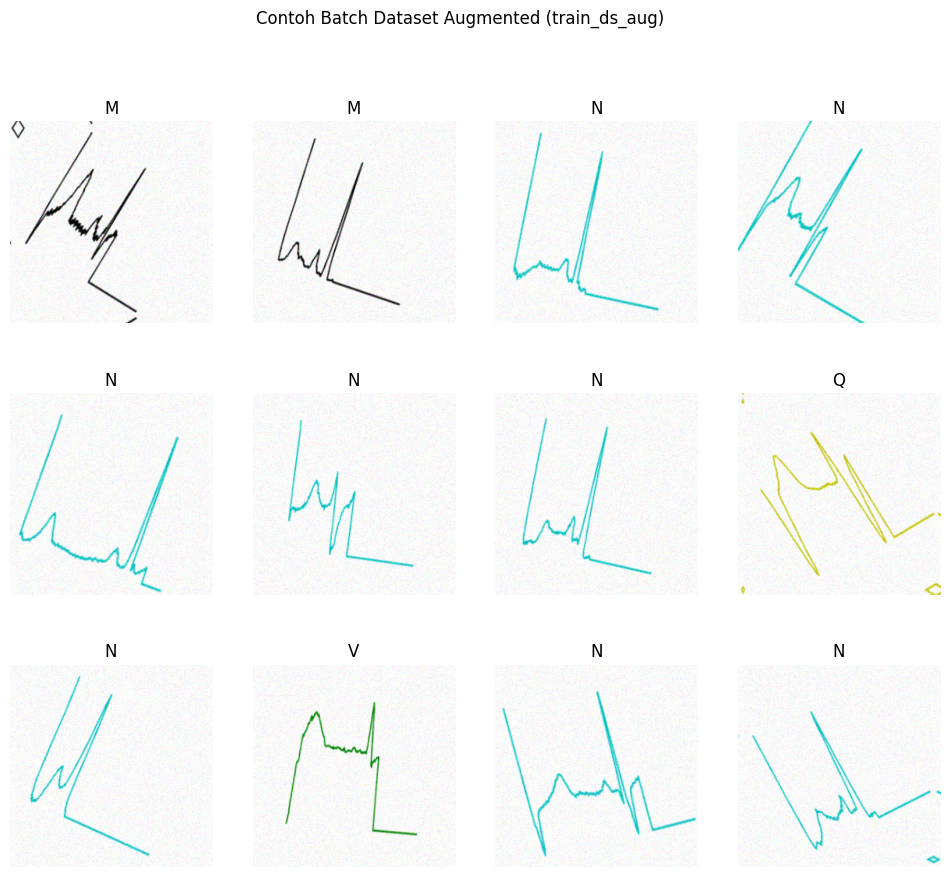

In [ ]:
# import tensorflow as tf
# import matplotlib.pyplot as plt
# import numpy as np
# import os

# DATA_DIR = r"C:\Users\LENOVO\Downloads\PEMROSESAN SINYAL DIGITAL\ECG\ECG_Image_data"
# train_dir = os.path.join(DATA_DIR, "train")
# test_dir  = os.path.join(DATA_DIR, "test")

# print("Train dir:", train_dir)
# print("Test dir :", test_dir)

# IMG_SIZE = 260
# BATCH_SIZE = 32
# SEED = 42

# train_ds = tf.keras.preprocessing.image_dataset_from_directory(
#     train_dir,
#     seed=SEED,
#     image_size=(IMG_SIZE, IMG_SIZE),
#     batch_size=BATCH_SIZE,
#     shuffle=True
# )

# test_ds = tf.keras.preprocessing.image_dataset_from_directory(
#     test_dir,
#     seed=SEED,
#     image_size=(IMG_SIZE, IMG_SIZE),
#     batch_size=BATCH_SIZE,
#     shuffle=False
# )

# class_names = train_ds.class_names
# num_classes = len(class_names)
# print("Kelas:", class_names)
# print("Jumlah kelas:", num_classes)

# # Normalisasi
# normalization_layer = tf.keras.layers.Rescaling(1./255)
# train_ds_norm = train_ds.map(lambda x, y: (normalization_layer(x), y))
# test_ds_norm  = test_ds.map(lambda x, y: (normalization_layer(x), y))

# # Augmentasi ringan
# data_augmentation_basic = tf.keras.Sequential([
#     tf.keras.layers.RandomRotation(0.10),
#     tf.keras.layers.RandomZoom(0.10),
# ])

# def add_gaussian_noise(x, std=0.05):
#     noise = tf.random.normal(shape=tf.shape(x), mean=0.0, stddev=std)
#     return tf.clip_by_value(x + noise, 0.0, 1.0)

# gaussian_noise_layer = tf.keras.layers.Lambda(lambda x: add_gaussian_noise(x))

# def full_augmentation(x):
#     x = data_augmentation_basic(x, training=True)
#     x = gaussian_noise_layer(x, training=True)
#     return x

# train_ds_aug = train_ds_norm.map(
#     lambda x, y: (full_augmentation(x), y),
#     num_parallel_calls=tf.data.AUTOTUNE
# )

# AUTOTUNE = tf.data.AUTOTUNE
# train_ds_aug = train_ds_aug.prefetch(buffer_size=AUTOTUNE)
# test_ds_norm  = test_ds_norm.prefetch(buffer_size=AUTOTUNE)

# # Visualisasi cepat
# plt.figure(figsize=(12, 10))
# plt.suptitle("Contoh Batch Dataset Augmented (train_ds_aug)")
# for images, labels in train_ds_aug.take(1):
#     for i in range(12):
#         ax = plt.subplot(3, 4, i + 1)
#         plt.imshow(images[i].numpy())
#         label = class_names[labels[i]]
#         plt.title(label)
#         plt.axis("off")
# plt.show()


EDA RAW DATA

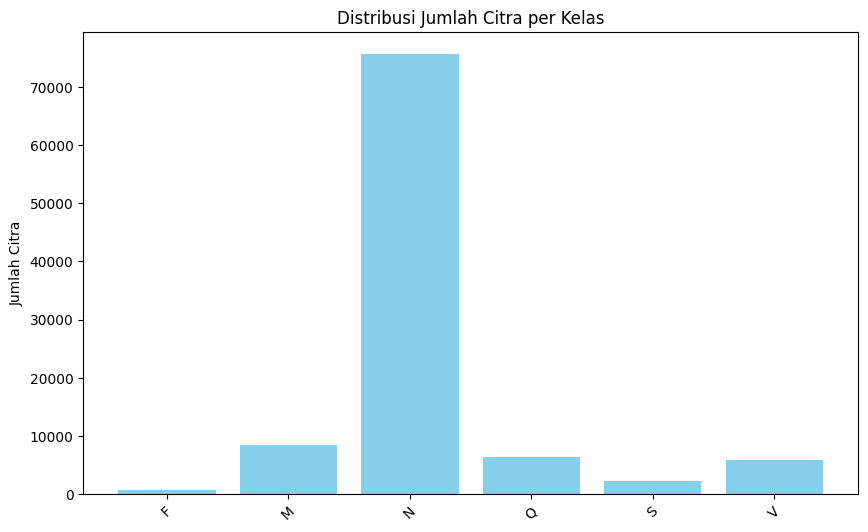

Distribusi kelas: {'F': 642, 'M': 8405, 'N': 75709, 'Q': 6431, 'S': 2223, 'V': 5789}


In [2]:
from collections import Counter

class_counts = {}

for class_name in class_names:
    class_path = os.path.join(train_dir, class_name)
    class_counts[class_name] = len(os.listdir(class_path))

plt.figure(figsize=(10, 6))
plt.bar(class_counts.keys(), class_counts.values(), color='skyblue')
plt.xticks(rotation=45)
plt.title("Distribusi Jumlah Citra per Kelas")
plt.ylabel("Jumlah Citra")
plt.show()

print("Distribusi kelas:", class_counts)


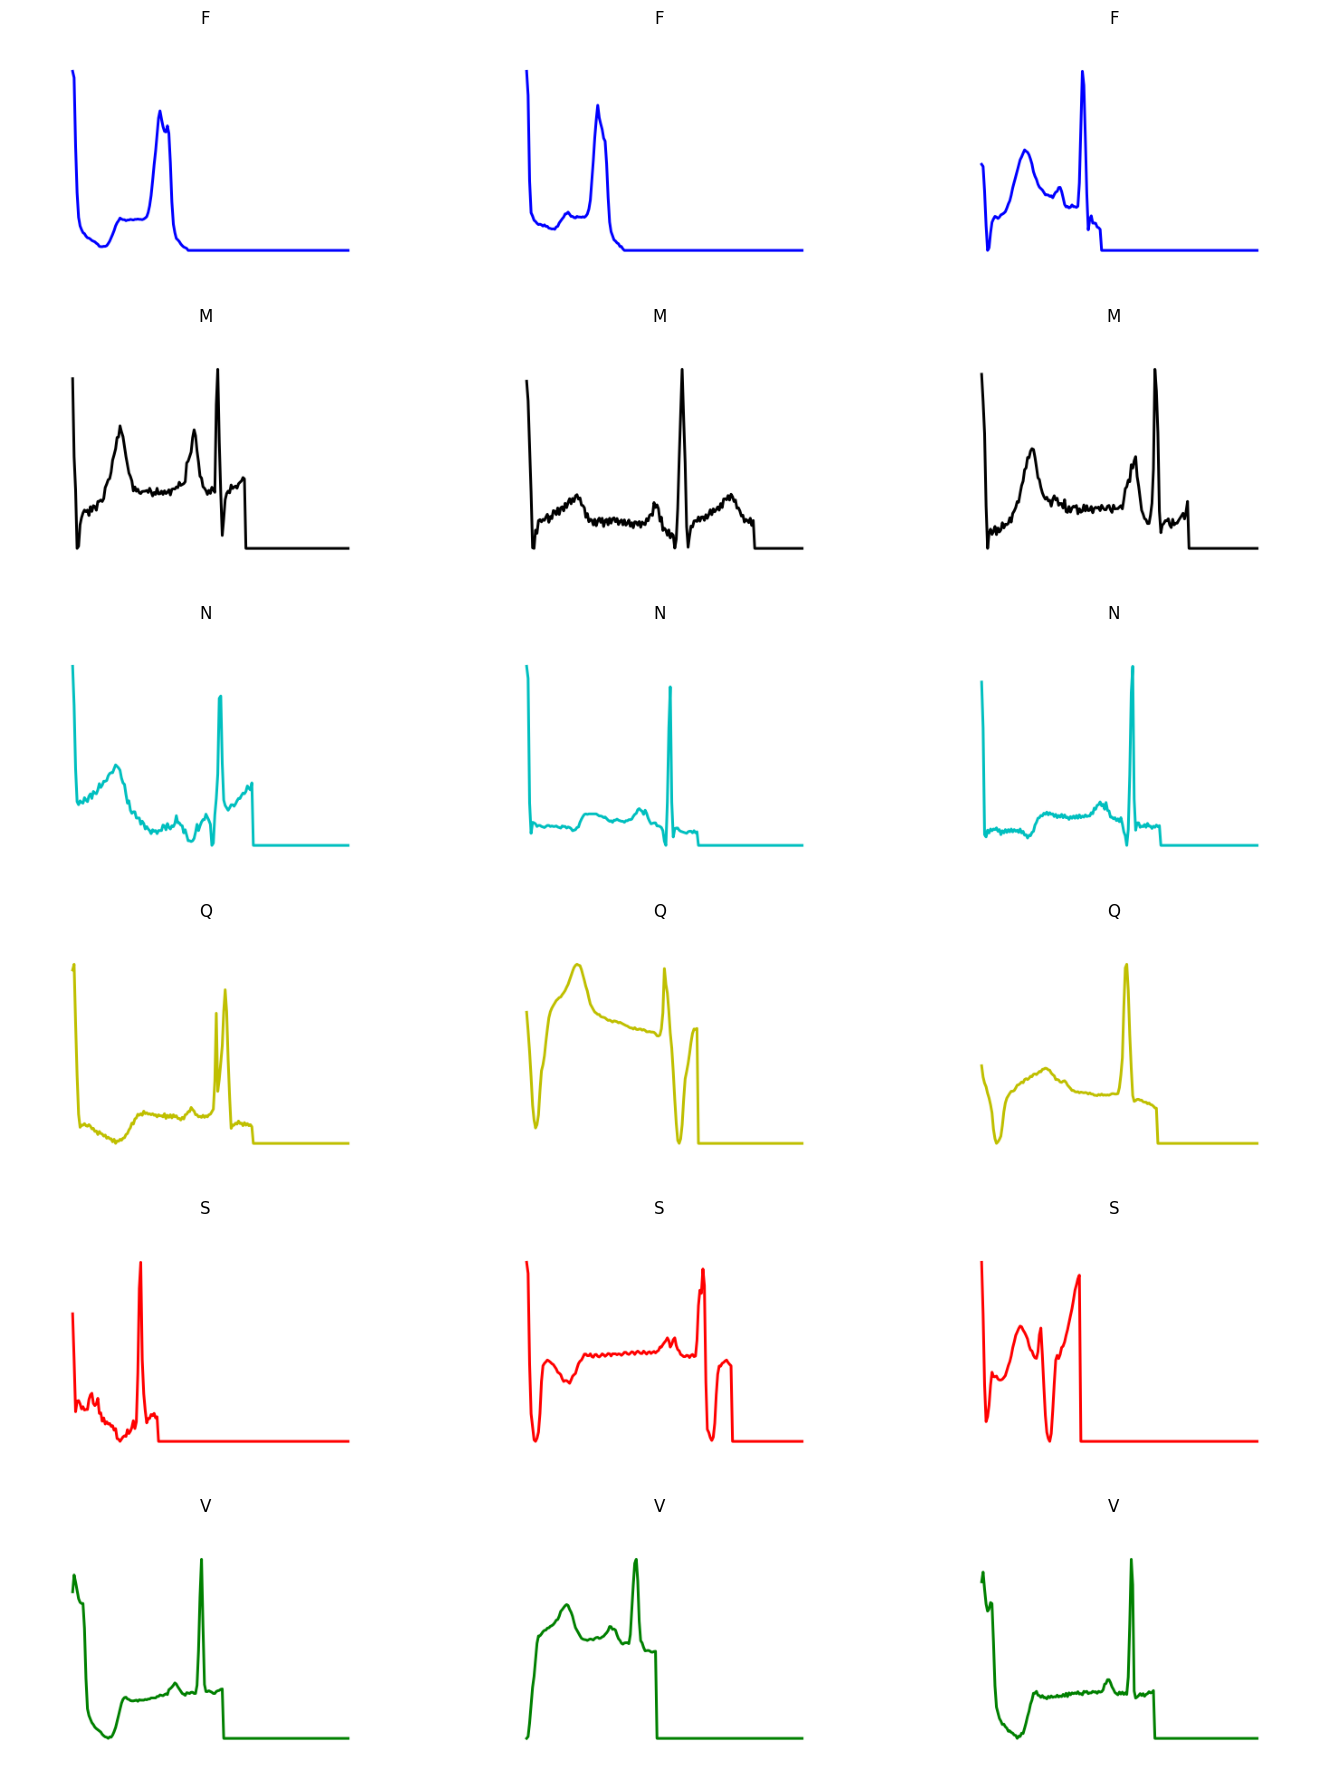

In [3]:
import random
import matplotlib.image as mpimg

plt.figure(figsize=(14, len(class_names) * 3))

for idx, class_name in enumerate(class_names):
    class_path = os.path.join(train_dir, class_name)
    sample_images = random.sample(os.listdir(class_path), 3)

    for i, img_name in enumerate(sample_images):
        img_path = os.path.join(class_path, img_name)
        img = mpimg.imread(img_path)

        plt.subplot(len(class_names), 3, idx * 3 + i + 1)
        plt.imshow(img)
        plt.title(f"{class_name}")
        plt.axis("off")

plt.tight_layout()
plt.show()


SIGNAL ANALYSIS

PENDEKATAN

Kita akan melakukan:

A. Waveform Pattern Insight

Untuk citra line-plot ECG, kita bisa ambil:

Puncak paling terang (atau paling tinggi secara vertikal)

Hitung jarak antar puncak (RR interval)

Visualisasikan R-peak dari citra

B. Spectrogram Insight

Bila citra adalah spectrogram:

Hitung frekuensi dominan

Energi tiap band frekuensi

Time–frequency energy evolution

C. Extracting Statistical Features

Dari citra apa pun, kita bisa ambil:

Entropy

Energy

Zero Crossing Rate (berdasarkan kontur waveform)

Peak energy density

A. Ekstraksi Waveform dari Citra ECG


[INFO] Mengambil satu citra ECG dari dataset
[INFO] Path citra: C:\Users\LENOVO\Downloads\PEMROSESAN SINYAL DIGITAL\ECG\ECG_Image_data\train\F\F1.png
[INFO] Citra berhasil dibaca
[OUTPUT] Dimensi citra: (288, 432, 3)
[INFO] Mulai ekstraksi waveform dari citra ECG
[INFO] Citra dikonversi ke grayscale
[INFO] Citra di-invert untuk menonjolkan sinyal
[INFO] Gaussian Blur diterapkan untuk reduksi noise
[INFO] Waveform diekstraksi (max intensitas per kolom)
[OUTPUT] Panjang waveform: 432
[INFO] Tren linear dihilangkan dari waveform

[INFO] Mulai deteksi R-peaks
[INFO] Threshold R-peak: 60.82730488441645
[OUTPUT] Jumlah R-peaks terdeteksi: 10
[OUTPUT] Indeks R-peaks: [ 71  85  95 107 120 131 147 159 182 200]


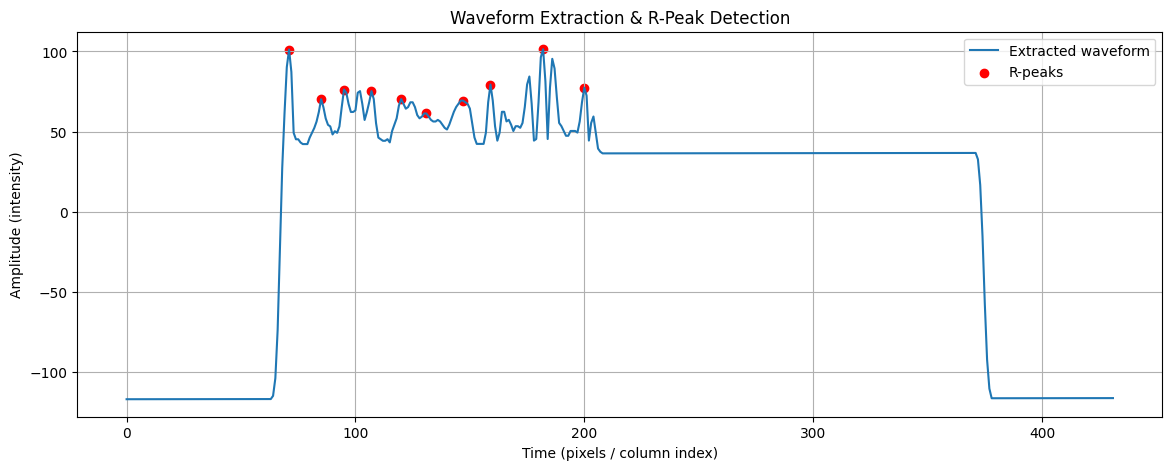


[INFO] Visualisasi waveform dan R-peaks ditampilkan

[OUTPUT] RR intervals (jarak antar R-peak):
[14 10 12 13 11 16 12 23 18]
[OUTPUT] RR interval rata-rata: 14.333333333333334
[OUTPUT] RR interval minimum: 10
[OUTPUT] RR interval maksimum: 23


In [3]:
import cv2 
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, detrend
import os

# Fungsi ekstraksi waveform dari citra ECG tipe line-plot
def extract_waveform_from_image(img):
    """
    Mengambil waveform dari citra ECG tipe line-plot.
    img: input citra BGR (cv2.imread)
    return: waveform 1D (numpy array)
    """
    print("[INFO] Mulai ekstraksi waveform dari citra ECG")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    print("[INFO] Citra dikonversi ke grayscale")

    gray = 255 - gray
    print("[INFO] Citra di-invert untuk menonjolkan sinyal")

    gray = cv2.GaussianBlur(gray, (7, 7), 0)
    print("[INFO] Gaussian Blur diterapkan untuk reduksi noise")

    waveform = np.max(gray, axis=0)
    print("[INFO] Waveform diekstraksi (max intensitas per kolom)")
    print("[OUTPUT] Panjang waveform:", len(waveform))

    waveform = detrend(waveform)
    print("[INFO] Tren linear dihilangkan dari waveform")

    return waveform

# Fungsi deteksi R-peaks pada waveform
def analyze_r_peaks(waveform, height_factor=0.6):
    """
    waveform: 1D numpy array hasil ekstraksi
    height_factor: threshold relatif terhadap puncak maksimum
    return: indeks R-peaks
    """
    print("\n[INFO] Mulai deteksi R-peaks")

    threshold = height_factor * np.max(waveform)
    print("[INFO] Threshold R-peak:", threshold)

    peaks, properties = find_peaks(
        waveform,
        height=threshold,
        distance=10
    )

    print("[OUTPUT] Jumlah R-peaks terdeteksi:", len(peaks))
    print("[OUTPUT] Indeks R-peaks:", peaks)

    return peaks


print("\n[INFO] Mengambil satu citra ECG dari dataset")

img_path = os.path.join(
    train_dir,
    class_names[0],
    os.listdir(os.path.join(train_dir, class_names[0]))[0]
)

print("[INFO] Path citra:", img_path)

img = cv2.imread(img_path)
print("[INFO] Citra berhasil dibaca")
print("[OUTPUT] Dimensi citra:", img.shape)

# Ekstraksi waveform
waveform = extract_waveform_from_image(img)

# Deteksi R-peaks
peaks = analyze_r_peaks(waveform)

# Visualisasi waveform & R-peaks
plt.figure(figsize=(14,5))
plt.plot(waveform, label="Extracted waveform")
plt.scatter(peaks, waveform[peaks], color='red', label='R-peaks')
plt.title("Waveform Extraction & R-Peak Detection")
plt.xlabel("Time (pixels / column index)")
plt.ylabel("Amplitude (intensity)")
plt.legend()
plt.grid(True)
plt.show()

print("\n[INFO] Visualisasi waveform dan R-peaks ditampilkan")

# Hitung RR intervals
rr_intervals = np.diff(peaks)
print("\n[OUTPUT] RR intervals (jarak antar R-peak):")
print(rr_intervals)

if len(rr_intervals) > 0:
    print("[OUTPUT] RR interval rata-rata:", np.mean(rr_intervals))
    print("[OUTPUT] RR interval minimum:", np.min(rr_intervals))
    print("[OUTPUT] RR interval maksimum:", np.max(rr_intervals))
else:
    print("[WARNING] RR interval tidak dapat dihitung (R-peak < 2)")


B. Analisis Spectrogram-Based Features


[INFO] Menjalankan analisis spektrogram
[INFO] Mulai analisis spektrogram citra
[INFO] Citra dikonversi ke grayscale
[INFO] Normalisasi intensitas grayscale ke rentang [0, 1]
[OUTPUT] Frequency energy profile dihitung
[OUTPUT] Panjang vektor frequency energy: 288
[OUTPUT] Indeks frekuensi dominan: 0
[OUTPUT] Energi spektral total: 122148.47


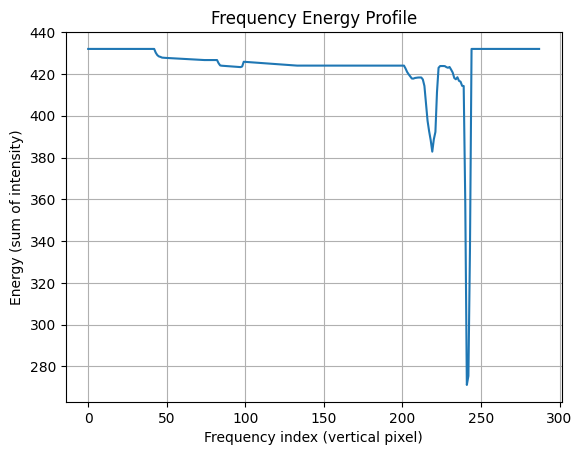


[INFO] Visualisasi profil energi frekuensi ditampilkan
[RESULT] Dominant frequency index: 0
[RESULT] Total spectral energy: 122148.47


In [ ]:
def analyze_spectrogram(img):
    print("[INFO] Mulai analisis spektrogram citra")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    print("[INFO] Citra dikonversi ke grayscale")

    gray = gray.astype(np.float32) / 255.0
    print("[INFO] Normalisasi intensitas grayscale ke rentang [0, 1]")

    # Sum energi setiap frekuensi (sumbu vertikal)
    freq_energy = np.sum(gray, axis=1)
    print("[OUTPUT] Frequency energy profile dihitung")
    print("[OUTPUT] Panjang vektor frequency energy:", len(freq_energy))

    # Dominant frequency (frekuensi dengan energi paling tinggi)
    dominant_freq = np.argmax(freq_energy)
    print("[OUTPUT] Indeks frekuensi dominan:", dominant_freq)

    # Energi total
    total_energy = np.sum(gray)
    print("[OUTPUT] Energi spektral total:", total_energy)

    return freq_energy, dominant_freq, total_energy


print("\n[INFO] Menjalankan analisis spektrogram")

freq_energy, dom_freq, E = analyze_spectrogram(img)

plt.plot(freq_energy)
plt.title("Frequency Energy Profile")
plt.xlabel("Frequency index (vertical pixel)")
plt.ylabel("Energy (sum of intensity)")
plt.grid(True)
plt.show()

print("\n[INFO] Visualisasi profil energi frekuensi ditampilkan")

print("[RESULT] Dominant frequency index:", dom_freq)
print("[RESULT] Total spectral energy:", E)


C. Ekstraksi Fitur Statistik dari Citra

Energy → energi gelombang

Entropy → kompleksitas ritme

ZCR → banyaknya perubahan arah → indikator aritmia

Contrast/Homogeneity → tekstur grafis sinyal

KLASIFIKASI DAN INSIGHT TAMBAHAN


=== Loading C:\Users\LENOVO\Downloads\PEMROSESAN SINYAL DIGITAL\ECG\ECG_Image_data\train ===
> Kelas 'F' : 642 gambar | Dipakai: 19 (3%)


Processing F: 100%|██████████| 19/19 [00:00<00:00, 83.91it/s]


> Kelas 'M' : 8405 gambar | Dipakai: 252 (3%)


Processing M: 100%|██████████| 252/252 [00:02<00:00, 120.06it/s]


> Kelas 'N' : 75709 gambar | Dipakai: 2271 (3%)


Processing N: 100%|██████████| 2271/2271 [00:17<00:00, 126.82it/s]


... (15 outputs left out)

Processing S: 100%|██████████| 16/16 [00:00<00:00, 152.25it/s]


> Kelas 'V' : 1447 gambar | Dipakai: 43 (3%)


Processing V: 100%|██████████| 43/43 [00:00<00:00, 128.42it/s]



Train shape: (2973, 260, 260, 3) Labels: (2973,)
Test shape : (741, 260, 260, 3) Labels: (741,)


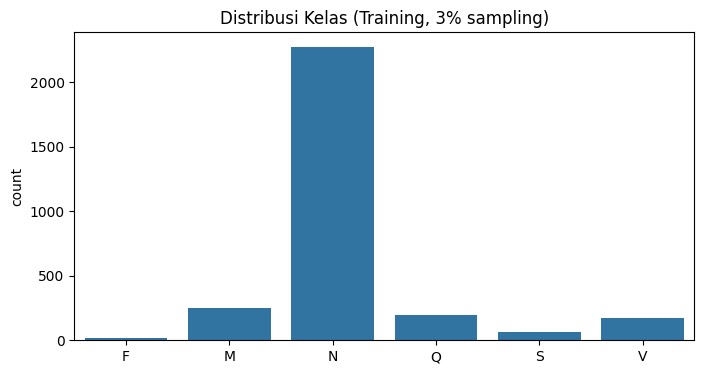


Ekstraksi fitur TRAIN...


100%|██████████| 2973/2973 [01:48<00:00, 27.48it/s]



Ekstraksi fitur TEST...


100%|██████████| 741/741 [00:25<00:00, 29.36it/s]


Train features: (2973, 8255)
Test features : (741, 8255)

Tuning hyperparameters...
Fitting 3 folds for each of 64 candidates, totalling 192 fits

=== BEST PARAMS ===
{'pca__n_components': 80, 'svm__C': 20, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}

=== BEST CV SCORE ===
0.9781365623948873

Evaluasi test set...

Accuracy : 0.9824561403508771

Classification Report:
               precision    recall  f1-score   support

           F       0.75      0.75      0.75         4
           M       0.95      0.94      0.94        63
           N       0.99      1.00      0.99       567
           Q       1.00      1.00      1.00        48
           S       0.93      0.88      0.90        16
           V       1.00      0.86      0.93        43

    accuracy                           0.98       741
   macro avg       0.94      0.90      0.92       741
weighted avg       0.98      0.98      0.98       741



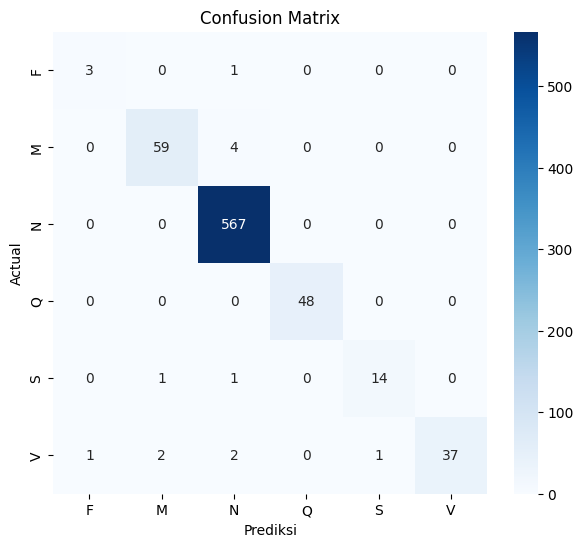

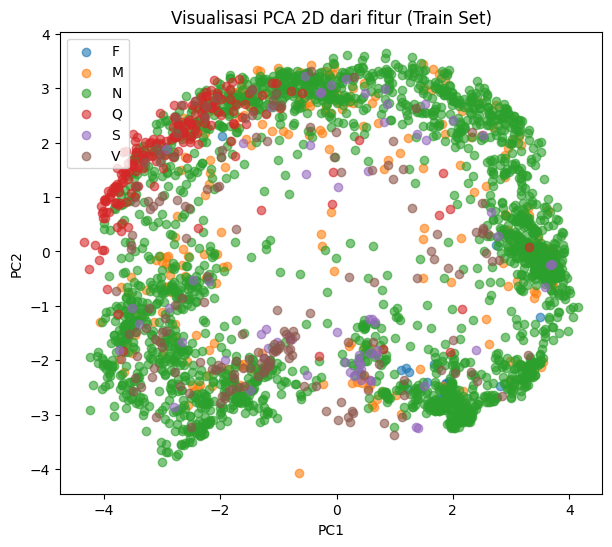

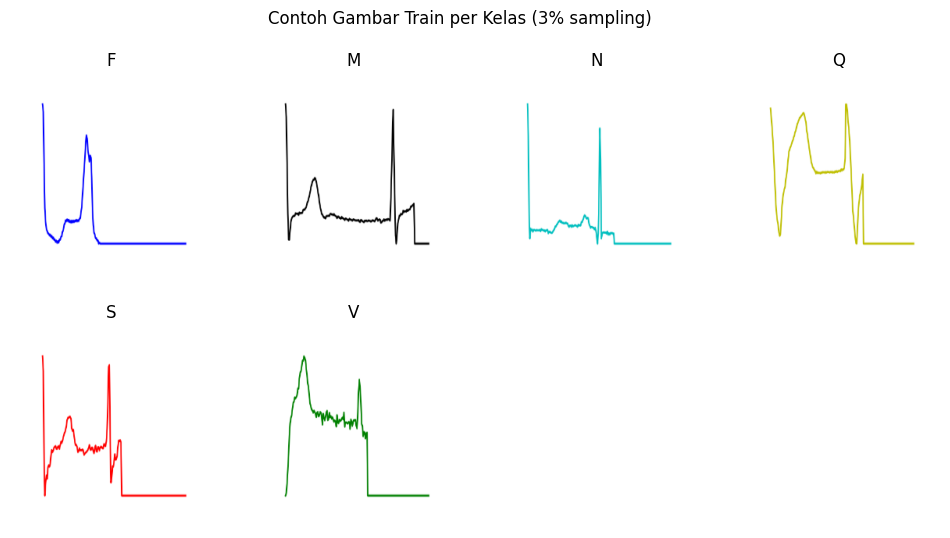


SELESAI ✔


In [5]:
import os
import cv2
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
import random

from skimage.feature import hog, local_binary_pattern
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. CONFIG
DATA_DIR = r"C:\Users\LENOVO\Downloads\PEMROSESAN SINYAL DIGITAL\ECG\ECG_Image_data"
IMG_SIZE = 260
SAMPLE_RATE = 0.03    # hanya 3% gambar per folder


# 2. LOAD DATASET (WITH SAMPLING 3%)
def load_images_from_split(split_path):
    X, y = [], []
    class_names = sorted(os.listdir(split_path))

    print(f"\n=== Loading {split_path} ===")
    
    for label, cls in enumerate(class_names):
        cls_path = os.path.join(split_path, cls)
        if not os.path.isdir(cls_path):
            continue
        
        files = [f for f in os.listdir(cls_path) if f.lower().endswith((".png", ".jpg", ".jpeg"))]

        # sampling 3%
        sample_size = max(1, int(len(files) * SAMPLE_RATE))
        sampled_files = random.sample(files, sample_size)

        print(f"> Kelas '{cls}' : {len(files)} gambar | Dipakai: {sample_size} (3%)")

        for fname in tqdm(sampled_files, desc=f"Processing {cls}"):
            img_path = os.path.join(cls_path, fname)
            img = cv2.imread(img_path)
            if img is None:
                continue

            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
            X.append(img)
            y.append(label)

    return np.array(X), np.array(y), class_names


# Load train and test
X_train_img, y_train, class_names = load_images_from_split(os.path.join(DATA_DIR, "train"))
X_test_img, y_test, _            = load_images_from_split(os.path.join(DATA_DIR, "test"))

print("\nTrain shape:", X_train_img.shape, "Labels:", y_train.shape)
print("Test shape :", X_test_img.shape, "Labels:", y_test.shape)


# EXTRA Visualisasi: Distribusi kelas setelah sampling
plt.figure(figsize=(8,4))
sns.countplot(x=[class_names[i] for i in y_train])
plt.title("Distribusi Kelas (Training, 3% sampling)")
plt.show()


# 3. FEATURE EXTRACTION
def extract_features(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # HOG
    hog_feat = hog(gray, orientations=9, pixels_per_cell=(16,16),
                   cells_per_block=(2,2), block_norm='L2', feature_vector=True)

    # LBP
    lbp = local_binary_pattern(gray, 8, 1, method="uniform")
    lbp_hist, _ = np.histogram(lbp, bins=59, range=(0, 59))
    lbp_hist = lbp_hist / (lbp_hist.sum() + 1e-6)

    # Color histogram
    hist_b = cv2.calcHist([img], [0], None, [32], [0,256]).flatten()
    hist_g = cv2.calcHist([img], [1], None, [32], [0,256]).flatten()
    hist_r = cv2.calcHist([img], [2], None, [32], [0,256]).flatten()
    
    color_hist = np.concatenate([hist_b, hist_g, hist_r])
    color_hist /= (color_hist.sum() + 1e-6)

    return np.concatenate([hog_feat, lbp_hist, color_hist])


print("\nEkstraksi fitur TRAIN...")
X_train = np.array([extract_features(img) for img in tqdm(X_train_img)])

print("\nEkstraksi fitur TEST...")
X_test = np.array([extract_features(img) for img in tqdm(X_test_img)])

print("Train features:", X_train.shape)
print("Test features :", X_test.shape)


# 4. PIPELINE (Scaler → PCA → SVM)
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("svm", SVC(probability=True))
])

# 5. TUNING SVM
param_grid = {
    "pca__n_components": [30, 50, 80, 100],
    "svm__C": [1, 5, 10, 20],
    "svm__gamma": ["scale", 0.01, 0.005, 0.001],
    "svm__kernel": ["rbf"]
}

print("\nTuning hyperparameters...")
grid = GridSearchCV(pipe, param_grid, cv=3, scoring="accuracy", n_jobs=-1, verbose=2)
grid.fit(X_train, y_train)

print("\n=== BEST PARAMS ===")
print(grid.best_params_)

print("\n=== BEST CV SCORE ===")
print(grid.best_score_)


# 6. EVALUASI
best_model = grid.best_estimator_

print("\nEvaluasi test set...")
y_pred = best_model.predict(X_test)

print("\nAccuracy :", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)


# 7. VISUALISASI CONFUSION MATRIX
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.xlabel("Prediksi")
plt.ylabel("Actual")
plt.show()


# 8. VISUALISASI PCA 2D (SETELAH TRAINING)
pca_vis = PCA(n_components=2).fit_transform(X_train)

plt.figure(figsize=(7,6))
for label in np.unique(y_train):
    plt.scatter(pca_vis[y_train==label,0], pca_vis[y_train==label,1], 
                label=class_names[label], alpha=0.6)

plt.legend()
plt.title("Visualisasi PCA 2D dari fitur (Train Set)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

# 9. VISUALISASI CONTOH GAMBAR PER KELAS (SETELAH SAMPLING)
plt.figure(figsize=(12,6))
for i, cls in enumerate(class_names):
    idx = np.where(y_train == i)[0]
    if len(idx) == 0:
        continue
    img = X_train_img[idx[0]]
    plt.subplot(2, 4, i+1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(cls)
    plt.axis("off")

plt.suptitle("Contoh Gambar Train per Kelas (3% sampling)")
plt.show()

print("\nSELESAI ✔")


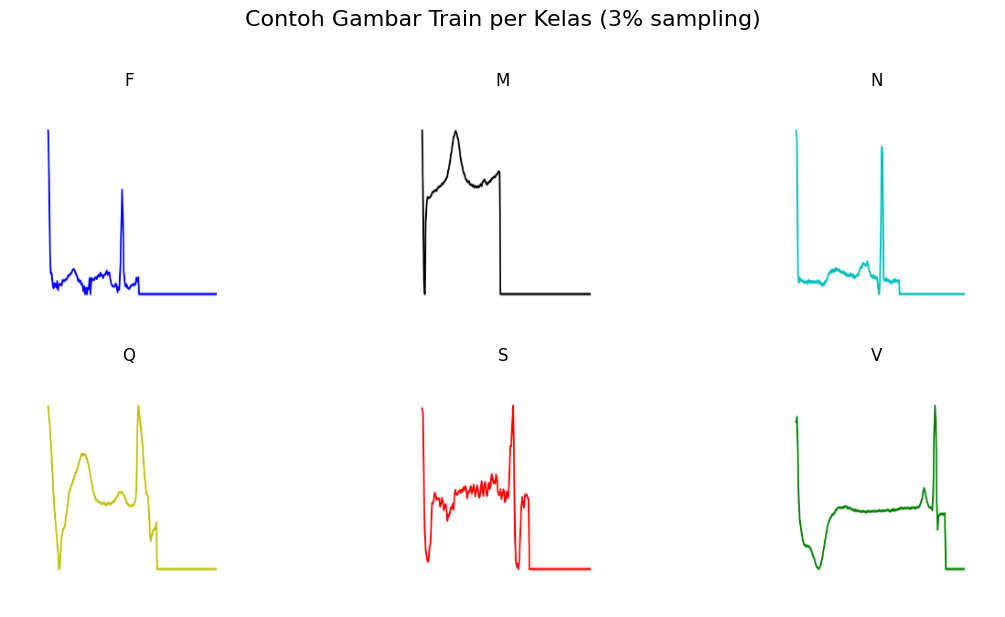

In [ ]:
import math

plt.figure(figsize=(12, 6))

cols = 3
rows = math.ceil(len(class_names) / cols)

for i, cls in enumerate(class_names):
    idx = np.where(y_train == i)[0]
    if len(idx) == 0:
        continue
    img = X_train_img[idx[0]]

    plt.subplot(rows, cols, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(cls, fontsize=12)
    plt.axis("off")

plt.suptitle("Contoh Gambar Train per Kelas (3% sampling)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


In [8]:
def visualize_feature_analysis(img, class_name="Unknown"):
    print("\n" + "="*70)
    print(f"[VISUAL ANALYSIS] Kelas: {class_name}")
    print("="*70)

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # ---------- HOG ----------
    _, hog_image = hog(
        gray,
        orientations=9,
        pixels_per_cell=(16,16),
        cells_per_block=(2,2),
        block_norm='L2',
        visualize=True,
        feature_vector=False
    )

    plt.figure(figsize=(6,5))
    plt.imshow(hog_image, cmap="inferno")
    plt.title("HOG – Gradient Feature")
    plt.axis("off")
    plt.show()

    print("[HOG OUTPUT]")
    print(" - Mean intensity :", hog_image.mean())
    print(" - Max intensity  :", hog_image.max())
    print(" - Std deviation  :", hog_image.std())
    print("-"*70)

    # ---------- LBP ----------
    lbp = local_binary_pattern(gray, 8, 1, method="uniform")

    plt.figure(figsize=(6,5))
    plt.imshow(lbp, cmap="gray")
    plt.title("LBP – Local Binary Pattern")
    plt.axis("off")
    plt.show()

    unique, counts = np.unique(lbp, return_counts=True)
    print("[LBP OUTPUT]")
    print(" - Jumlah pola unik :", len(unique))
    print(" - Pola dominan    :", unique[np.argmax(counts)])
    print(" - Frekuensi max   :", counts.max())
    print("-"*70)

    # ---------- FFT ----------
    f = np.fft.fft2(gray)
    fshift = np.fft.fftshift(f)
    fft_magnitude = np.log(np.abs(fshift) + 1)

    plt.figure(figsize=(6,5))
    plt.imshow(fft_magnitude, cmap="viridis")
    plt.title("FFT – Frequency Spectrum")
    plt.axis("off")
    plt.show()

    print("[FFT OUTPUT]")
    print(" - Energy min  :", fft_magnitude.min())
    print(" - Energy max  :", fft_magnitude.max())
    print(" - Energy mean :", fft_magnitude.mean())
    print("-"*70)

    # ---------- Waveform ----------
    waveform = np.mean(gray, axis=1)

    plt.figure(figsize=(6,4))
    plt.plot(waveform)
    plt.title("Waveform Projection")
    plt.xlabel("Row Index")
    plt.ylabel("Intensity")
    plt.show()

    print("[WAVEFORM OUTPUT]")
    print(" - Length :", len(waveform))
    print(" - Min    :", waveform.min())
    print(" - Max    :", waveform.max())
    print(" - Mean   :", waveform.mean())
    print("-"*70)

    # ---------- Histogram ----------
    hist_b = cv2.calcHist([img], [0], None, [32], [0,256])
    hist_g = cv2.calcHist([img], [1], None, [32], [0,256])
    hist_r = cv2.calcHist([img], [2], None, [32], [0,256])

    plt.figure(figsize=(6,4))
    plt.plot(hist_b, label="Blue")
    plt.plot(hist_g, label="Green")
    plt.plot(hist_r, label="Red")
    plt.title("Color Histogram")
    plt.legend()
    plt.show()

    print("[HISTOGRAM OUTPUT]")
    print(" - Blue total  :", hist_b.sum())
    print(" - Green total :", hist_g.sum())
    print(" - Red total   :", hist_r.sum())
    print("="*70)



[INFO] Menampilkan visualisasi analisis sinyal untuk tiap kelas...
[INFO] Total kelas: 6
[INFO] Daftar kelas: ['F', 'M', 'N', 'Q', 'S', 'V']

[INFO] Memproses kelas ke-0 → F
[INFO] Jumlah sampel pada kelas ini: 19
[INFO] Mengambil 1 sampel citra untuk visualisasi
[OUTPUT] Index data yang digunakan : 0
[OUTPUT] Dimensi citra             : (260, 260, 3)

[VISUAL ANALYSIS] Kelas: F


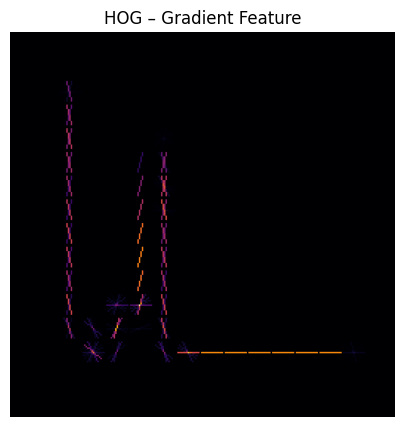

[HOG OUTPUT]
 - Mean intensity : 0.37140369371009563
 - Max intensity  : 66.56268119812012
 - Std deviation  : 3.355759530513017
----------------------------------------------------------------------


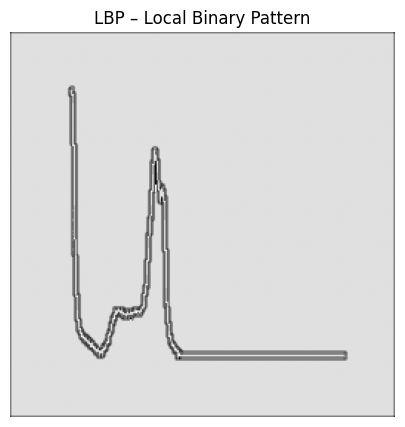

[LBP OUTPUT]
 - Jumlah pola unik : 9
 - Pola dominan    : 8.0
 - Frekuensi max   : 63578
----------------------------------------------------------------------


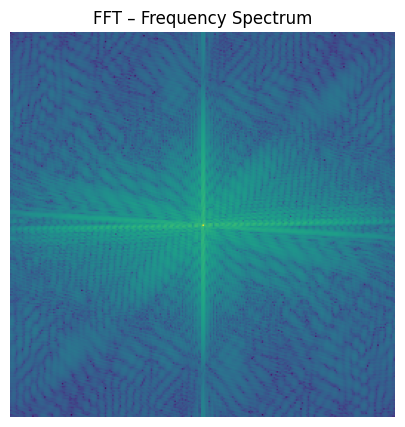

[FFT OUTPUT]
 - Energy min  : 1.063240170669524
 - Energy max  : 16.645831841689695
 - Energy mean : 6.761816237631872
----------------------------------------------------------------------


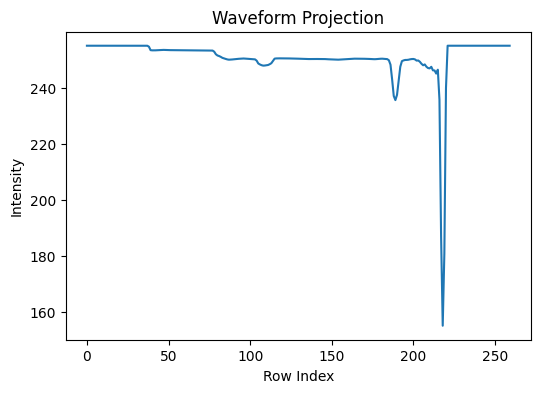

[WAVEFORM OUTPUT]
 - Length : 260
 - Min    : 155.1423076923077
 - Max    : 255.0
 - Mean   : 250.75303254437873
----------------------------------------------------------------------


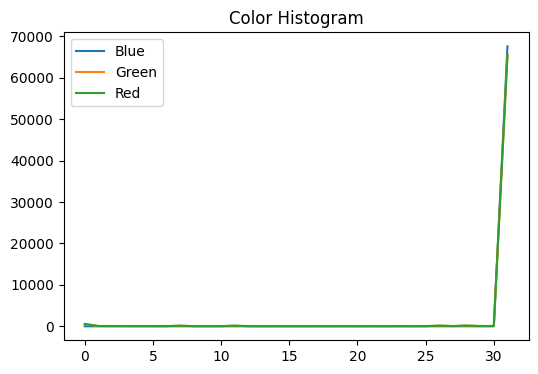

[HISTOGRAM OUTPUT]
 - Blue total  : 67600.0
 - Green total : 67600.0
 - Red total   : 67600.0
[INFO] Analisis fitur untuk kelas 'F' selesai

[INFO] Memproses kelas ke-1 → M
[INFO] Jumlah sampel pada kelas ini: 252
[INFO] Mengambil 1 sampel citra untuk visualisasi
[OUTPUT] Index data yang digunakan : 19
[OUTPUT] Dimensi citra             : (260, 260, 3)

[VISUAL ANALYSIS] Kelas: M


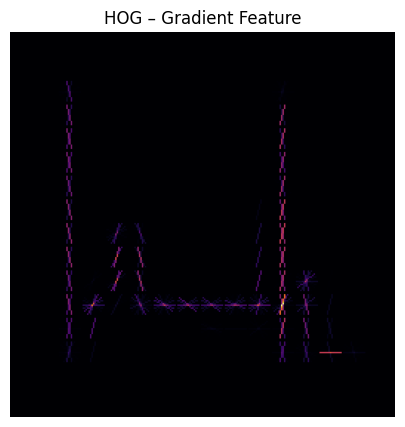

[HOG OUTPUT]
 - Mean intensity : 0.5469568487041845
 - Max intensity  : 104.85076236724854
 - Std deviation  : 4.030633337639485
----------------------------------------------------------------------


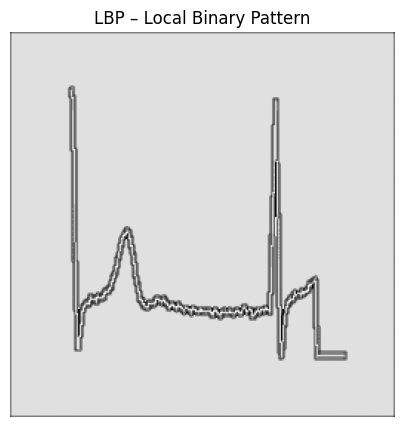

[LBP OUTPUT]
 - Jumlah pola unik : 9
 - Pola dominan    : 8.0
 - Frekuensi max   : 62739
----------------------------------------------------------------------


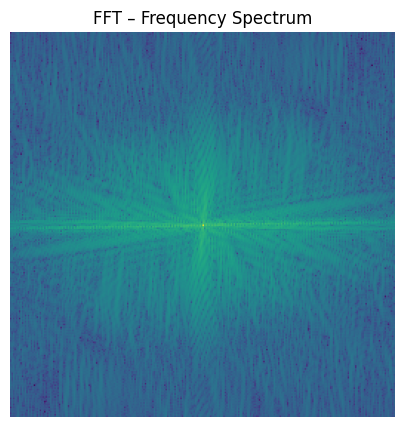

[FFT OUTPUT]
 - Energy min  : 1.4620962253902905
 - Energy max  : 16.637099005747302
 - Energy mean : 7.229818193554841
----------------------------------------------------------------------


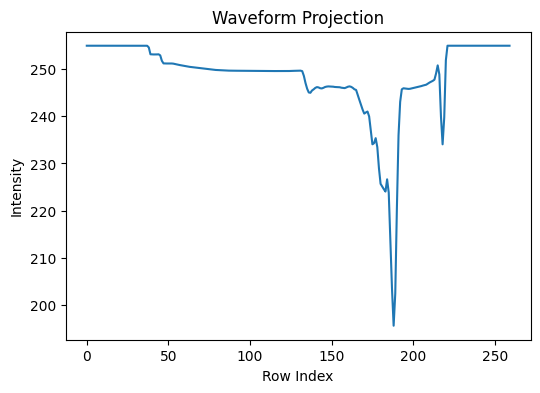

[WAVEFORM OUTPUT]
 - Length : 260
 - Min    : 195.55384615384617
 - Max    : 255.0
 - Mean   : 248.57278106508875
----------------------------------------------------------------------


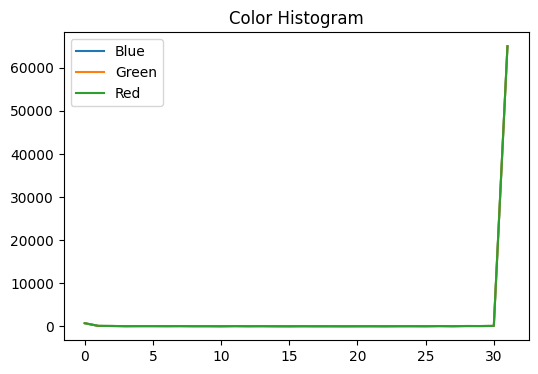

[HISTOGRAM OUTPUT]
 - Blue total  : 67600.0
 - Green total : 67600.0
 - Red total   : 67600.0
[INFO] Analisis fitur untuk kelas 'M' selesai

[INFO] Memproses kelas ke-2 → N
[INFO] Jumlah sampel pada kelas ini: 2271
[INFO] Mengambil 1 sampel citra untuk visualisasi
[OUTPUT] Index data yang digunakan : 271
[OUTPUT] Dimensi citra             : (260, 260, 3)

[VISUAL ANALYSIS] Kelas: N


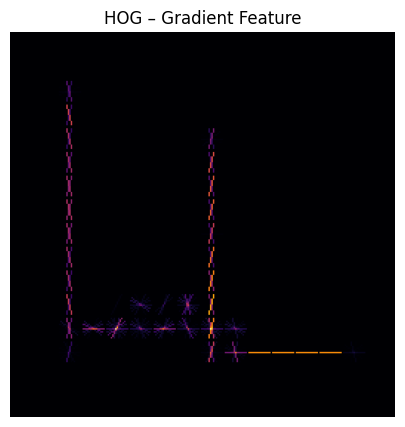

[HOG OUTPUT]
 - Mean intensity : 0.20521934948398693
 - Max intensity  : 35.664869368076324
 - Std deviation  : 1.7461730255915047
----------------------------------------------------------------------


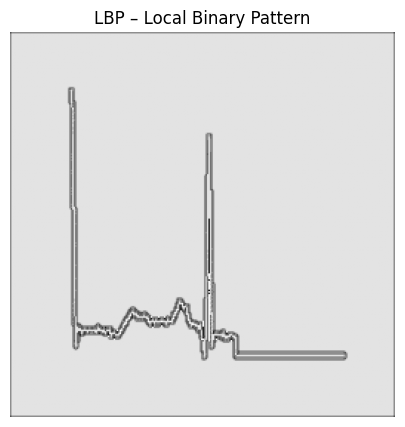

[LBP OUTPUT]
 - Jumlah pola unik : 10
 - Pola dominan    : 8.0
 - Frekuensi max   : 63648
----------------------------------------------------------------------


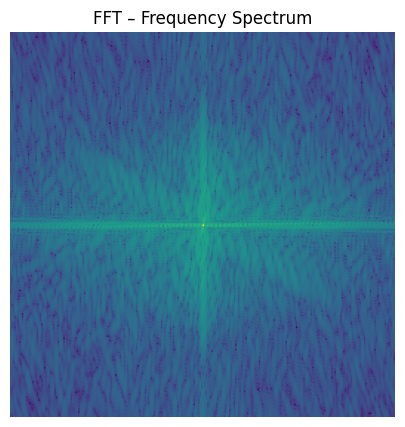

[FFT OUTPUT]
 - Energy min  : 1.4506270753163306
 - Energy max  : 16.652555962055384
 - Energy mean : 6.347326162282211
----------------------------------------------------------------------


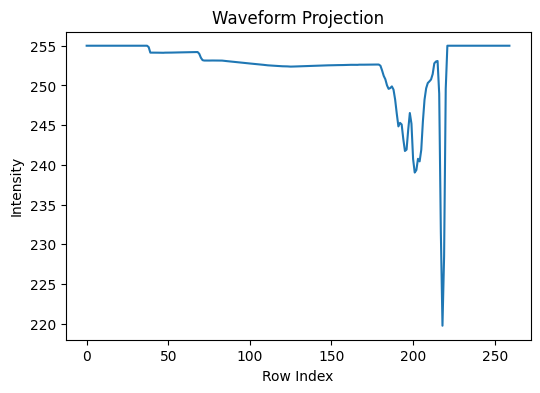

[WAVEFORM OUTPUT]
 - Length : 260
 - Min    : 219.73076923076923
 - Max    : 255.0
 - Mean   : 252.44480769230768
----------------------------------------------------------------------


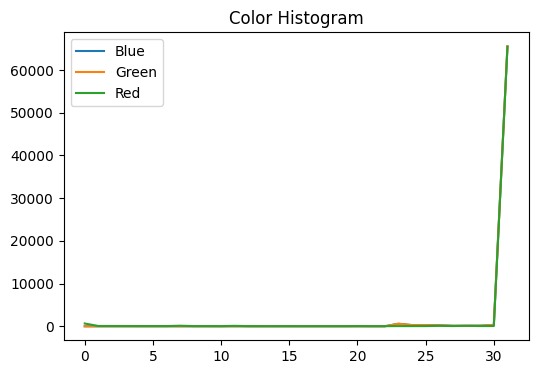

[HISTOGRAM OUTPUT]
 - Blue total  : 67600.0
 - Green total : 67600.0
 - Red total   : 67600.0
[INFO] Analisis fitur untuk kelas 'N' selesai

[INFO] Memproses kelas ke-3 → Q
[INFO] Jumlah sampel pada kelas ini: 192
[INFO] Mengambil 1 sampel citra untuk visualisasi
[OUTPUT] Index data yang digunakan : 2542
[OUTPUT] Dimensi citra             : (260, 260, 3)

[VISUAL ANALYSIS] Kelas: Q


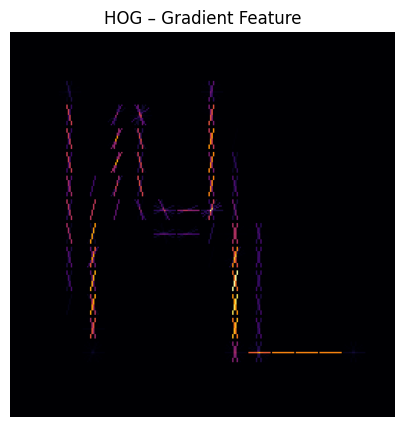

[HOG OUTPUT]
 - Mean intensity : 0.21190034737242883
 - Max intensity  : 25.91156268119812
 - Std deviation  : 1.6402128914701077
----------------------------------------------------------------------


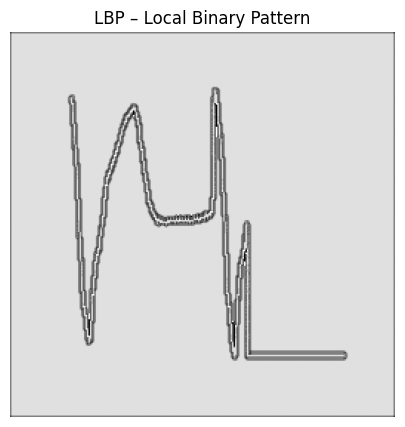

[LBP OUTPUT]
 - Jumlah pola unik : 9
 - Pola dominan    : 8.0
 - Frekuensi max   : 62278
----------------------------------------------------------------------


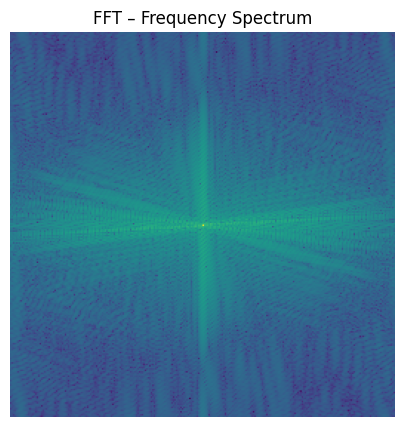

[FFT OUTPUT]
 - Energy min  : 0.1751959745683743
 - Energy max  : 16.653458850906915
 - Energy mean : 5.859268705364905
----------------------------------------------------------------------


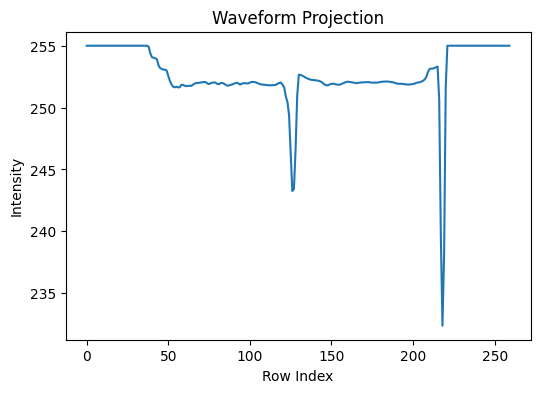

[WAVEFORM OUTPUT]
 - Length : 260
 - Min    : 232.3653846153846
 - Max    : 255.0
 - Mean   : 252.6728402366864
----------------------------------------------------------------------


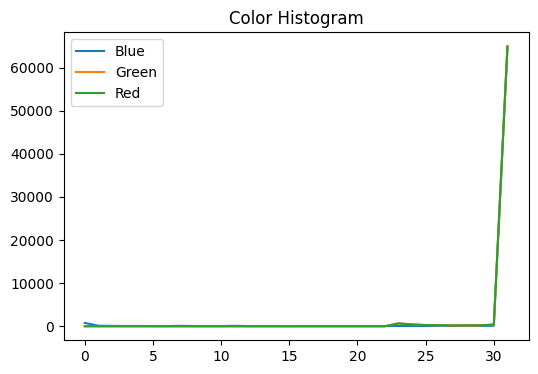

[HISTOGRAM OUTPUT]
 - Blue total  : 67600.0
 - Green total : 67600.0
 - Red total   : 67600.0
[INFO] Analisis fitur untuk kelas 'Q' selesai

[INFO] Memproses kelas ke-4 → S
[INFO] Jumlah sampel pada kelas ini: 66
[INFO] Mengambil 1 sampel citra untuk visualisasi
[OUTPUT] Index data yang digunakan : 2734
[OUTPUT] Dimensi citra             : (260, 260, 3)

[VISUAL ANALYSIS] Kelas: S


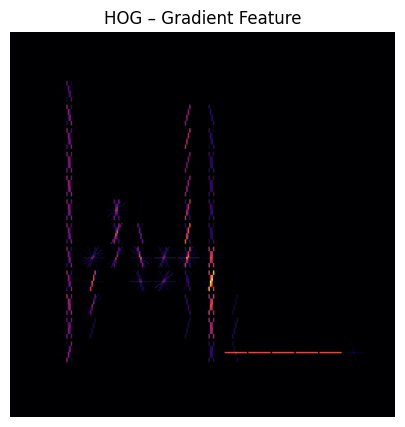

[HOG OUTPUT]
 - Mean intensity : 0.38843504306424914
 - Max intensity  : 66.18047749996185
 - Std deviation  : 2.9628336076635216
----------------------------------------------------------------------


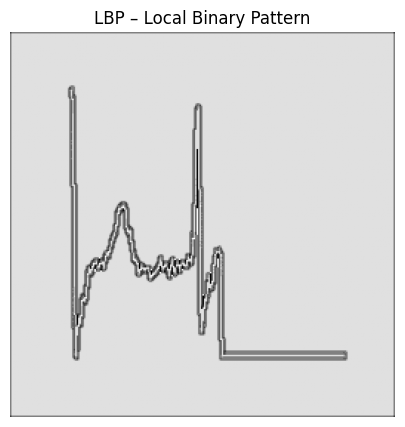

[LBP OUTPUT]
 - Jumlah pola unik : 9
 - Pola dominan    : 8.0
 - Frekuensi max   : 62777
----------------------------------------------------------------------


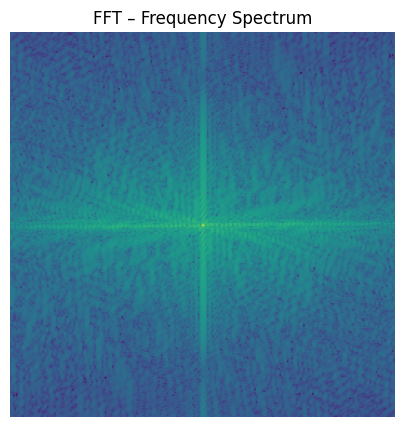

[FFT OUTPUT]
 - Energy min  : 1.051083608118447
 - Energy max  : 16.64399219572201
 - Energy mean : 6.6861253320072
----------------------------------------------------------------------


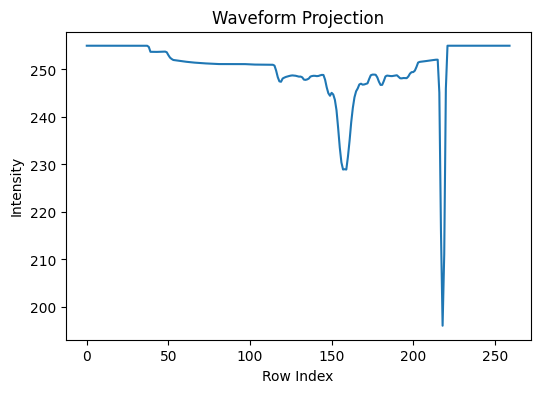

[WAVEFORM OUTPUT]
 - Length : 260
 - Min    : 196.05
 - Max    : 255.0
 - Mean   : 250.2921597633136
----------------------------------------------------------------------


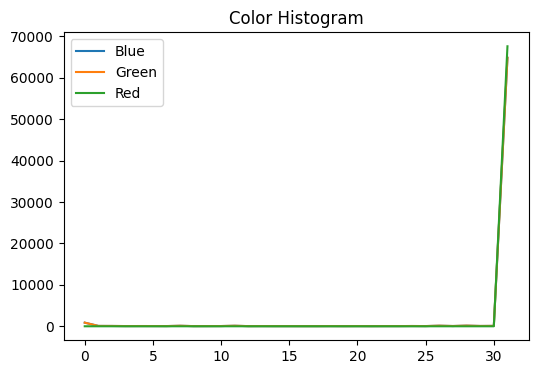

[HISTOGRAM OUTPUT]
 - Blue total  : 67600.0
 - Green total : 67600.0
 - Red total   : 67600.0
[INFO] Analisis fitur untuk kelas 'S' selesai

[INFO] Memproses kelas ke-5 → V
[INFO] Jumlah sampel pada kelas ini: 173
[INFO] Mengambil 1 sampel citra untuk visualisasi
[OUTPUT] Index data yang digunakan : 2800
[OUTPUT] Dimensi citra             : (260, 260, 3)

[VISUAL ANALYSIS] Kelas: V


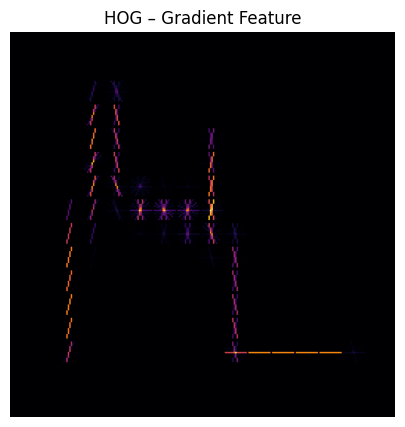

[HOG OUTPUT]
 - Mean intensity : 0.3289876361772385
 - Max intensity  : 53.76846182346344
 - Std deviation  : 2.8389929013617565
----------------------------------------------------------------------


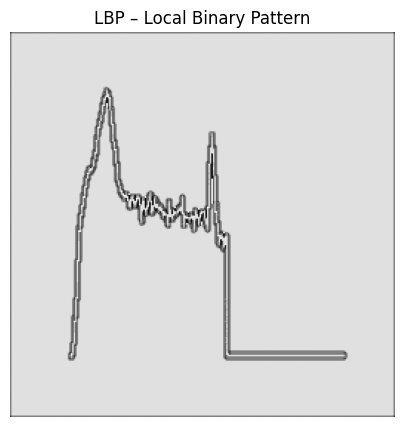

[LBP OUTPUT]
 - Jumlah pola unik : 9
 - Pola dominan    : 8.0
 - Frekuensi max   : 63285
----------------------------------------------------------------------


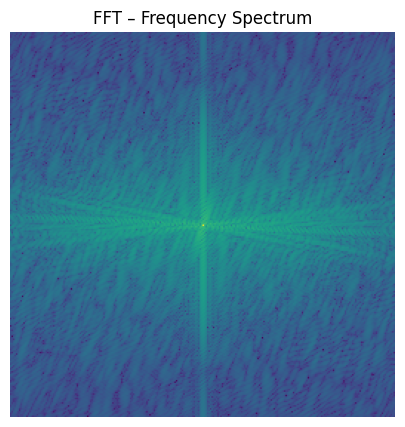

[FFT OUTPUT]
 - Energy min  : 1.554632875164213
 - Energy max  : 16.64662788337794
 - Energy mean : 6.724217583243539
----------------------------------------------------------------------


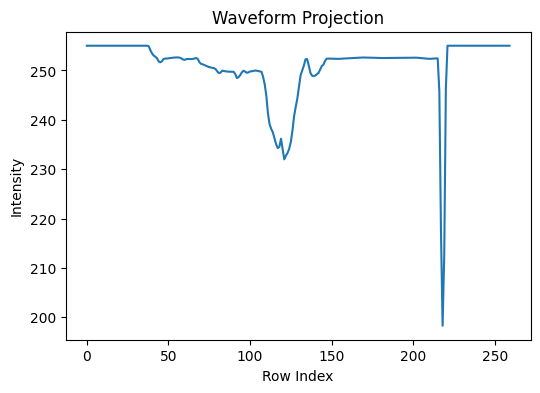

[WAVEFORM OUTPUT]
 - Length : 260
 - Min    : 198.31153846153848
 - Max    : 255.0
 - Mean   : 250.95272189349114
----------------------------------------------------------------------


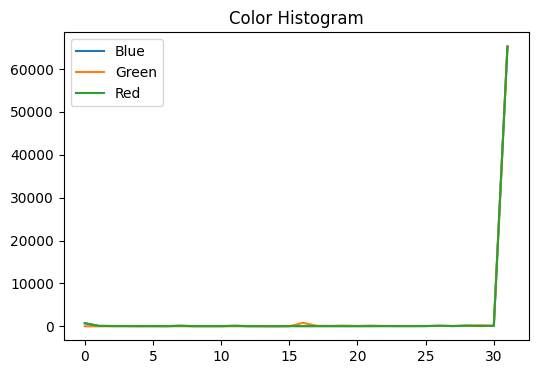

[HISTOGRAM OUTPUT]
 - Blue total  : 67600.0
 - Green total : 67600.0
 - Red total   : 67600.0
[INFO] Analisis fitur untuk kelas 'V' selesai


In [9]:
print("\n" + "="*70)
print("[INFO] Menampilkan visualisasi analisis sinyal untuk tiap kelas...")
print("[INFO] Total kelas:", len(class_names))
print("[INFO] Daftar kelas:", class_names)
print("="*70)

for i, cls in enumerate(class_names):
    print(f"\n[INFO] Memproses kelas ke-{i} → {cls}")

    idx = np.where(y_train == i)[0]
    print("[INFO] Jumlah sampel pada kelas ini:", len(idx))

    if len(idx) == 0:
        print("[WARNING] Tidak ada data untuk kelas ini, dilewati")
        print("-"*70)
        continue

    img = X_train_img[idx[0]]
    print("[INFO] Mengambil 1 sampel citra untuk visualisasi")
    print("[OUTPUT] Index data yang digunakan :", idx[0])
    print("[OUTPUT] Dimensi citra             :", img.shape)

    visualize_feature_analysis(img, class_name=cls)

    print(f"[INFO] Analisis fitur untuk kelas '{cls}' selesai")
    print("="*70)



In [ ]:
# from skimage.feature import graycomatrix, graycoprops
# import pywt

# def full_signal_insight_separate(img, class_name="Unknown"):
#     gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

#     # ========== Edge Detection ==========
#     sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0)
#     sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1)
#     canny = cv2.Canny(gray, 50, 150)

#     # ========== Histogram Gray ==========
#     hist_gray = cv2.calcHist([gray], [0], None, [256], [0, 256])

#     # ========== GLCM ==========
#     glcm = graycomatrix(gray, distances=[1], angles=[0], levels=256,
#                         symmetric=True, normed=True)
#     contrast = graycoprops(glcm, 'contrast')[0,0]
#     energy = graycoprops(glcm, 'energy')[0,0]
#     homogeneity = graycoprops(glcm, 'homogeneity')[0,0]

#     # ========== Wavelet ==========
#     LL, (LH, HL, HH) = pywt.dwt2(gray, 'haar')

#     # ========== Spectral Energy ==========
#     fft = np.fft.fft(gray.flatten())
#     spectral_energy = np.sum(np.abs(fft)**2)

#     # ========== Line Signals ==========
#     line_signal = gray[gray.shape[0]//2, :]
#     col_signal = np.mean(gray, axis=0)

#     # Sobel X
#     plt.figure(figsize=(6,5))
#     plt.imshow(sobel_x, cmap="gray")
#     plt.title(f"Sobel X – Kelas: {class_name}")
#     plt.axis("off")
#     plt.show()
#     print("Insight: Sobel X menonjolkan perubahan intensitas arah horizontal. Pada ECG, puncak QRS sering terlihat jelas.")

#     # Sobel Y
#     plt.figure(figsize=(6,5))
#     plt.imshow(sobel_y, cmap="gray")
#     plt.title("Sobel Y")
#     plt.axis("off")
#     plt.show()
#     print("Insight: Sobel Y menonjolkan kontur vertikal, berguna untuk melihat ketebalan garis ECG.")

#     # Canny
#     plt.figure(figsize=(6,5))
#     plt.imshow(canny, cmap="gray")
#     plt.title("Canny Edge Detector")
#     plt.axis("off")
#     plt.show()
#     print("Insight: Canny menghasilkan edge yang paling bersih, membantu mendeteksi pola QRS yang tajam.")

#     # Histogram Gray
#     plt.figure(figsize=(6,4))
#     plt.plot(hist_gray)
#     plt.title("Histogram Grayscale")
#     plt.show()
#     print("Insight: Histogram grayscale memberi gambaran distribusi intensitas. ECG biasanya dominan warna gelap.")

#     # Wavelet LL
#     plt.figure(figsize=(6,5))
#     plt.imshow(LL, cmap="gray")
#     plt.title("Wavelet LL (Low Frequency)")
#     plt.axis("off")
#     plt.show()
#     print("Insight: LL menampilkan bentuk global ECG tanpa detail—penting untuk membedakan baseline wandering.")

#     # Wavelet LH
#     plt.figure(figsize=(6,5))
#     plt.imshow(LH, cmap="gray")
#     plt.title("Wavelet LH (Horizontal High)")
#     plt.axis("off")
#     plt.show()
#     print("Insight: LH menonjolkan perubahan horizontal → sangat berkaitan dengan bentuk puncak QRS.")

#     # Wavelet HL
#     plt.figure(figsize=(6,5))
#     plt.imshow(HL, cmap="gray")
#     plt.title("Wavelet HL (Vertical High)")
#     plt.axis("off")
#     plt.show()
#     print("Insight: HL memperlihatkan detail vertikal, cocok untuk memisahkan noise vs sinyal.")

#     # Wavelet HH
#     plt.figure(figsize=(6,5))
#     plt.imshow(HH, cmap="gray")
#     plt.title("Wavelet HH (High-High)")
#     plt.axis("off")
#     plt.show()
#     print("Insight: HH menunjukkan komponen frekuensi tinggi—bagian paling sensitif terhadap noise.")

#     # Line Scan
#     plt.figure(figsize=(6,4))
#     plt.plot(line_signal)
#     plt.title("Line Scan – Middle Row")
#     plt.xlabel("Pixel Index")
#     plt.ylabel("Intensity")
#     plt.show()
#     print("Insight: Line scan mengubah citra ECG ke sinyal 1D. Puncak QRS terlihat sebagai spike intensitas.")

#     # Column Signal
#     plt.figure(figsize=(6,4))
#     plt.plot(col_signal)
#     plt.title("Column Mean Signal")
#     plt.xlabel("Column Index")
#     plt.ylabel("Intensity")
#     plt.show()
#     print("Insight: Column-mean menunjukkan aliran vertikal sinyal ECG untuk mengamati pola ritmis.")

#     # GLCM Features
#     plt.figure(figsize=(6,4))
#     plt.bar(["Contrast","Energy","Homogeneity"],
#             [contrast, energy, homogeneity])
#     plt.title("GLCM Texture Features")
#     plt.show()
#     print(f"Insight:\n- Contrast: {contrast:.4f}\n- Energy: {energy:.4f}\n- Homogeneity: {homogeneity:.4f}")
#     print("GLCM mendeskripsikan tekstur mikro yang membedakan kelas aritmia.")

#     # Spectral Energy
#     plt.figure(figsize=(6,4))
#     plt.text(0.1, 0.5, f"Spectral Energy:\n{spectral_energy:.2e}",
#              fontsize=16)
#     plt.axis("off")
#     plt.show()
#     print("Insight: Semakin besar energi spektral → semakin banyak komponen frekuensi tinggi (QRS tajam).")


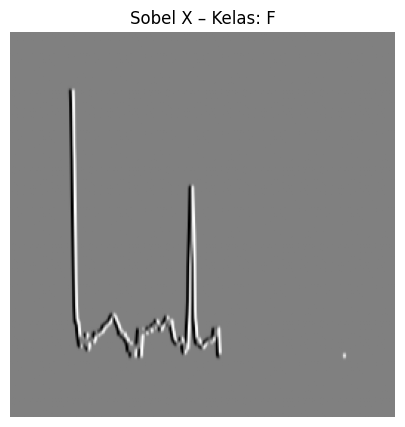

Insight: Sobel X menonjolkan perubahan intensitas arah horizontal. Pada ECG, puncak QRS sering terlihat jelas.


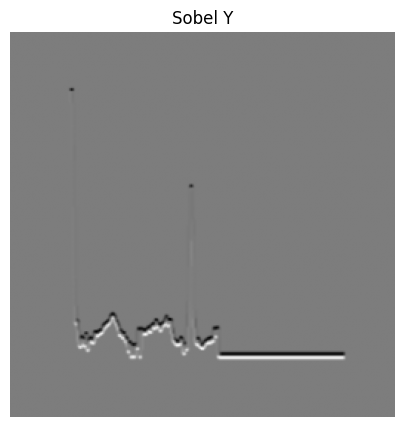

Insight: Sobel Y menonjolkan kontur vertikal, berguna untuk melihat ketebalan garis ECG.


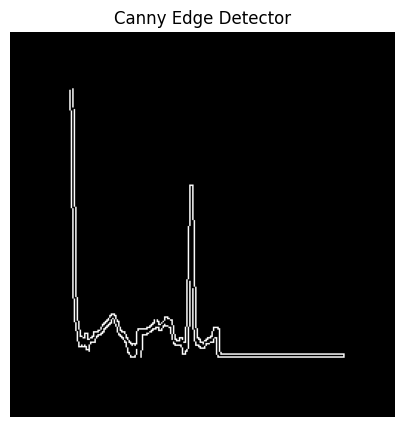

Insight: Canny menghasilkan edge yang paling bersih, membantu mendeteksi pola QRS yang tajam.


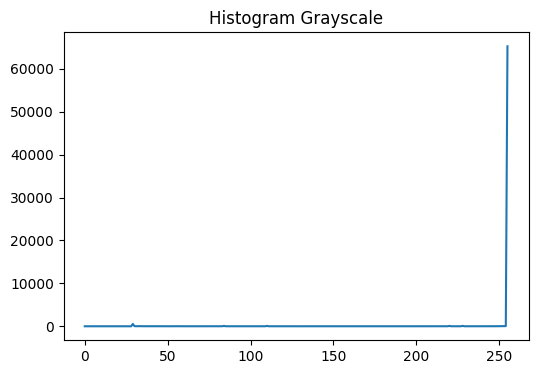

Insight: Histogram grayscale memberi gambaran distribusi intensitas. ECG biasanya dominan warna gelap.


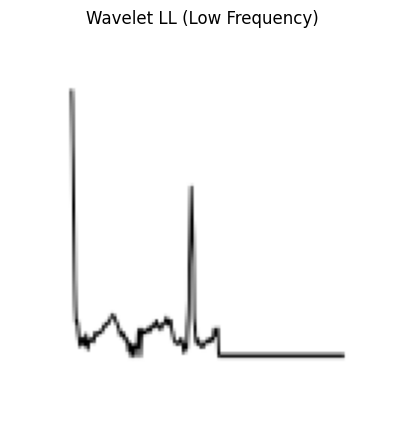

Insight: LL menampilkan bentuk global ECG tanpa detail—penting untuk membedakan baseline wandering.


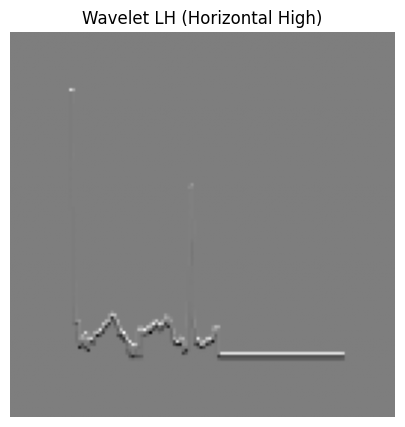

Insight: LH menonjolkan perubahan horizontal → sangat berkaitan dengan bentuk puncak QRS.


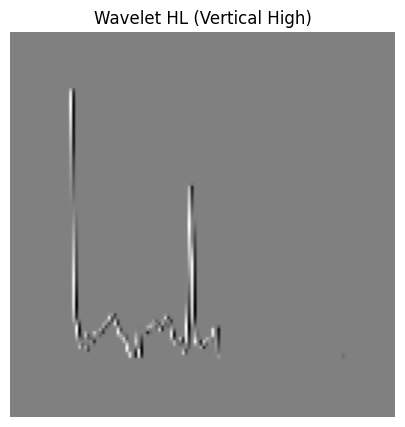

Insight: HL memperlihatkan detail vertikal, cocok untuk memisahkan noise vs sinyal.


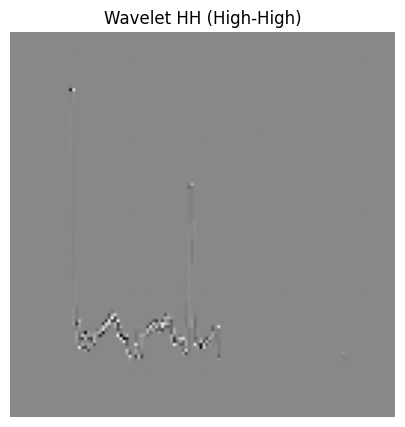

Insight: HH menunjukkan komponen frekuensi tinggi—bagian paling sensitif terhadap noise.


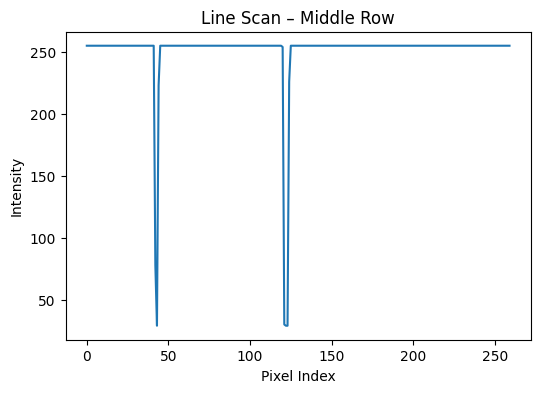

Insight: Line scan mengubah citra ECG ke sinyal 1D. Puncak QRS terlihat sebagai spike intensitas.


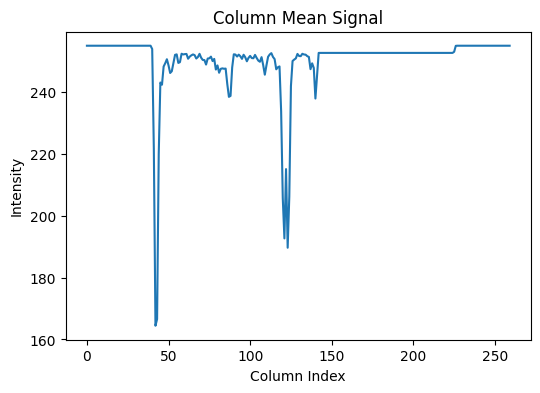

Insight: Column-mean menunjukkan aliran vertikal sinyal ECG untuk mengamati pola ritmis.


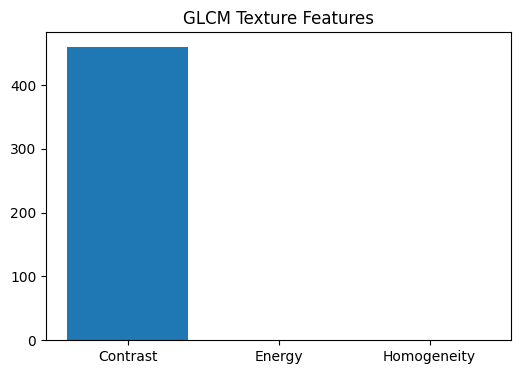

Insight:
- Contrast: 459.5481
- Energy: 0.9588
- Homogeneity: 0.9675
GLCM mendeskripsikan tekstur mikro yang membedakan kelas aritmia.


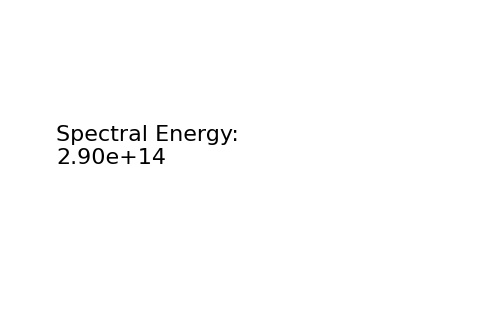

Insight: Semakin besar energi spektral → semakin banyak komponen frekuensi tinggi (QRS tajam).


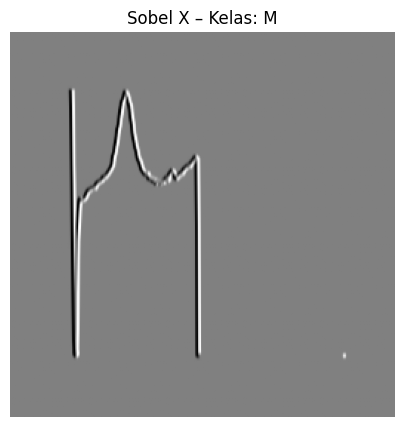

Insight: Sobel X menonjolkan perubahan intensitas arah horizontal. Pada ECG, puncak QRS sering terlihat jelas.


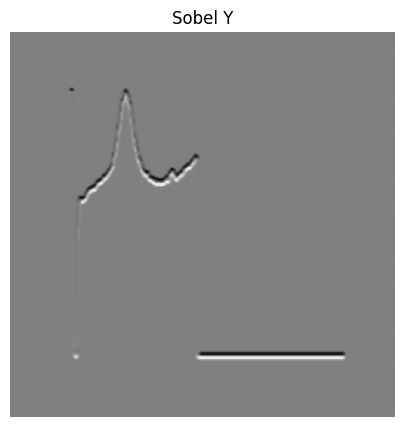

Insight: Sobel Y menonjolkan kontur vertikal, berguna untuk melihat ketebalan garis ECG.


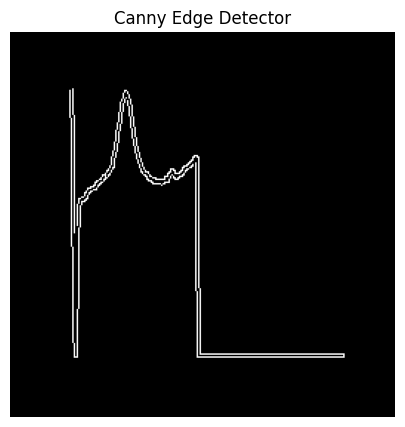

Insight: Canny menghasilkan edge yang paling bersih, membantu mendeteksi pola QRS yang tajam.


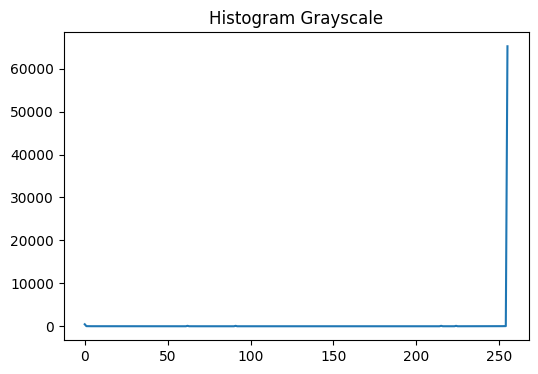

Insight: Histogram grayscale memberi gambaran distribusi intensitas. ECG biasanya dominan warna gelap.


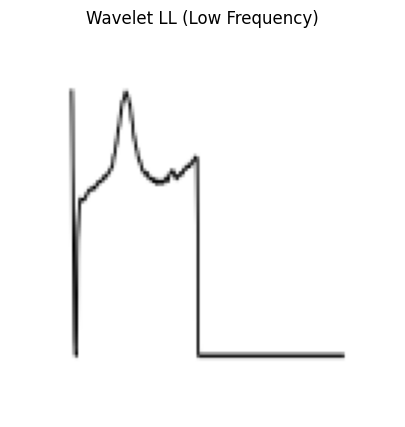

Insight: LL menampilkan bentuk global ECG tanpa detail—penting untuk membedakan baseline wandering.


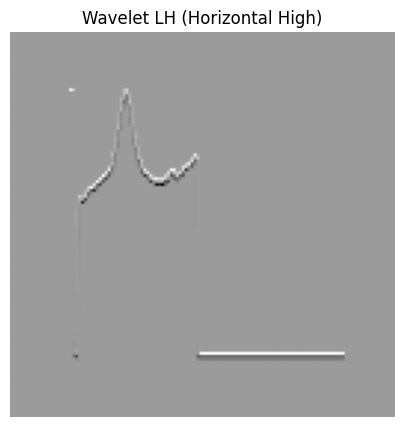

Insight: LH menonjolkan perubahan horizontal → sangat berkaitan dengan bentuk puncak QRS.


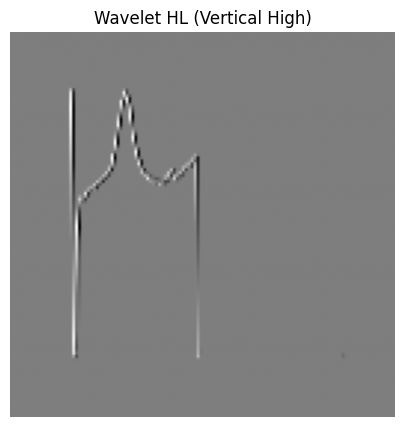

Insight: HL memperlihatkan detail vertikal, cocok untuk memisahkan noise vs sinyal.


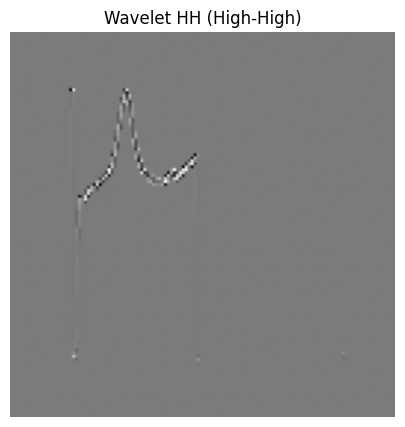

Insight: HH menunjukkan komponen frekuensi tinggi—bagian paling sensitif terhadap noise.


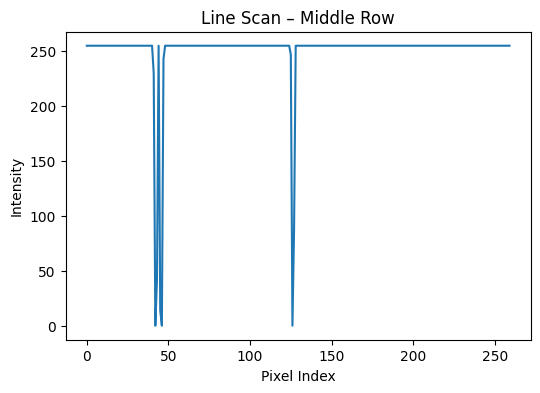

Insight: Line scan mengubah citra ECG ke sinyal 1D. Puncak QRS terlihat sebagai spike intensitas.


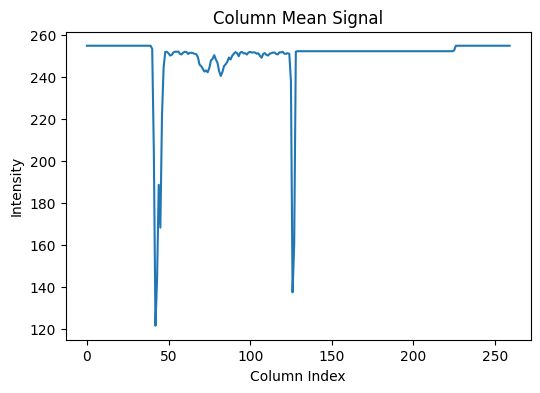

Insight: Column-mean menunjukkan aliran vertikal sinyal ECG untuk mengamati pola ritmis.


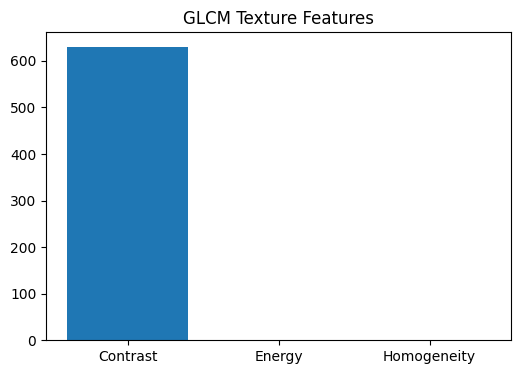

Insight:
- Contrast: 629.7817
- Energy: 0.9573
- Homogeneity: 0.9659
GLCM mendeskripsikan tekstur mikro yang membedakan kelas aritmia.


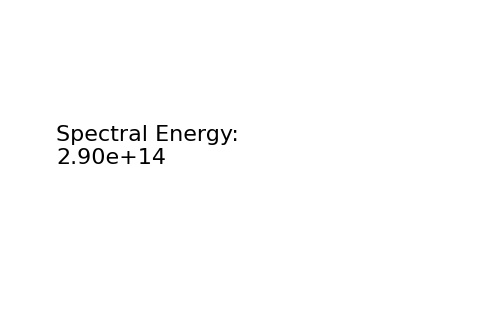

Insight: Semakin besar energi spektral → semakin banyak komponen frekuensi tinggi (QRS tajam).


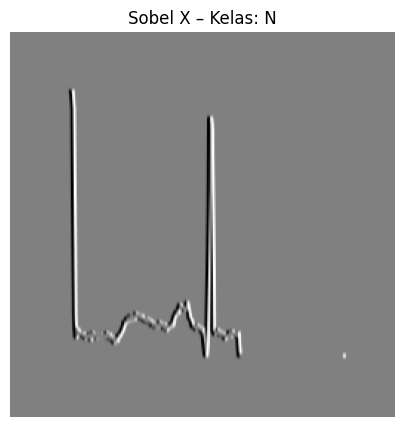

Insight: Sobel X menonjolkan perubahan intensitas arah horizontal. Pada ECG, puncak QRS sering terlihat jelas.


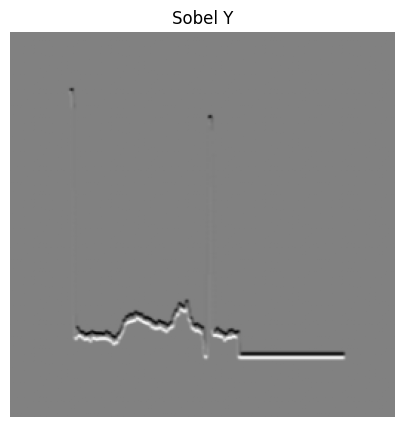

Insight: Sobel Y menonjolkan kontur vertikal, berguna untuk melihat ketebalan garis ECG.


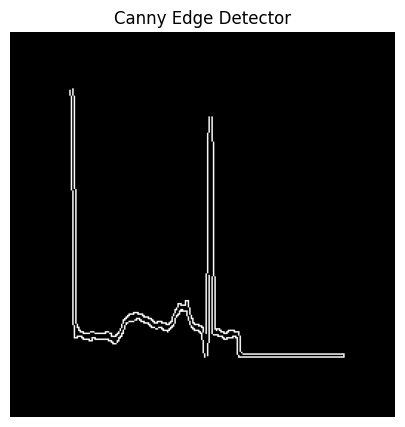

Insight: Canny menghasilkan edge yang paling bersih, membantu mendeteksi pola QRS yang tajam.


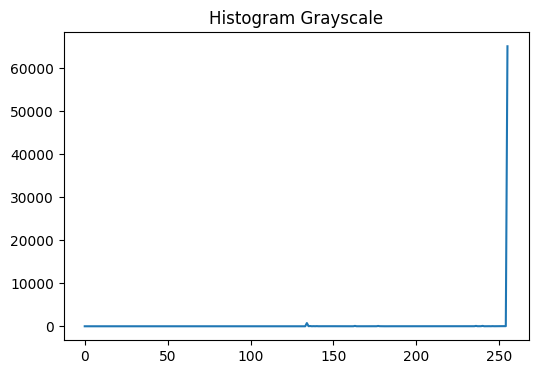

Insight: Histogram grayscale memberi gambaran distribusi intensitas. ECG biasanya dominan warna gelap.


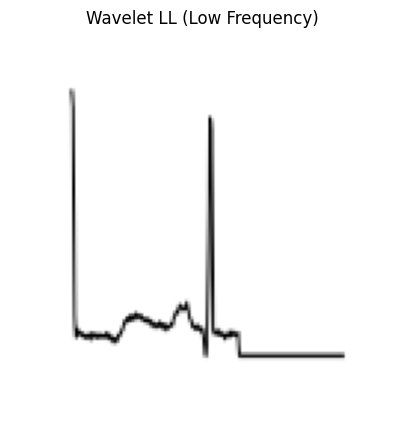

Insight: LL menampilkan bentuk global ECG tanpa detail—penting untuk membedakan baseline wandering.


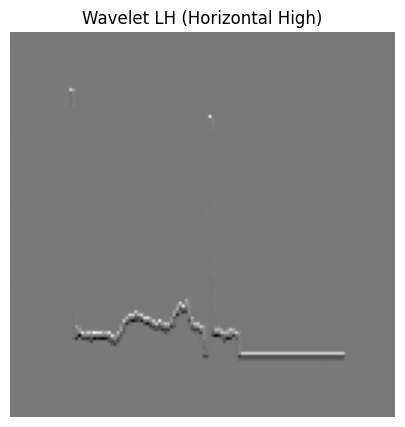

Insight: LH menonjolkan perubahan horizontal → sangat berkaitan dengan bentuk puncak QRS.


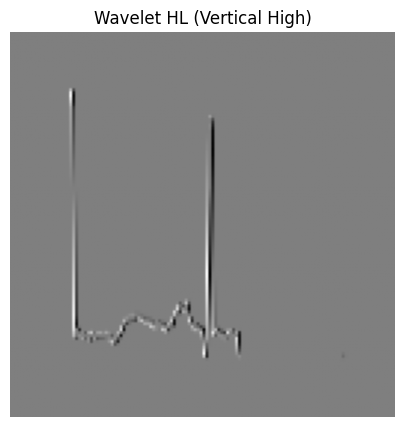

Insight: HL memperlihatkan detail vertikal, cocok untuk memisahkan noise vs sinyal.


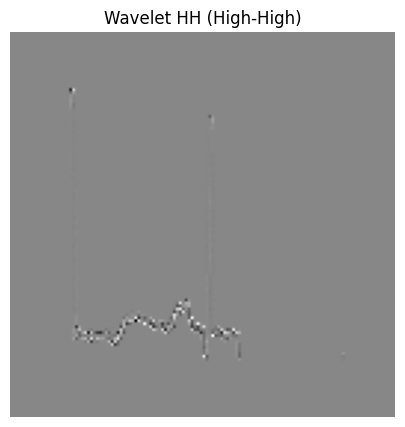

Insight: HH menunjukkan komponen frekuensi tinggi—bagian paling sensitif terhadap noise.


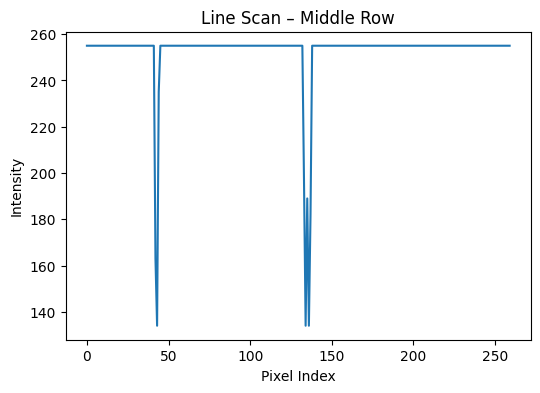

Insight: Line scan mengubah citra ECG ke sinyal 1D. Puncak QRS terlihat sebagai spike intensitas.


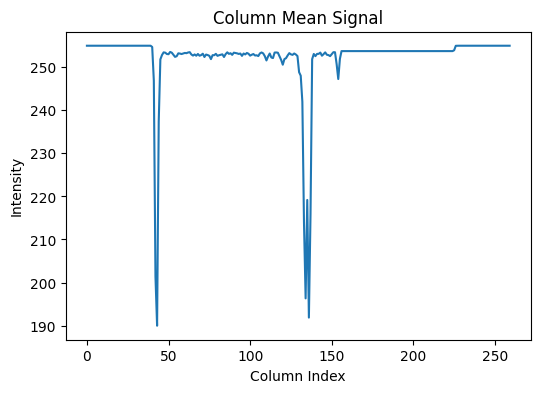

Insight: Column-mean menunjukkan aliran vertikal sinyal ECG untuk mengamati pola ritmis.


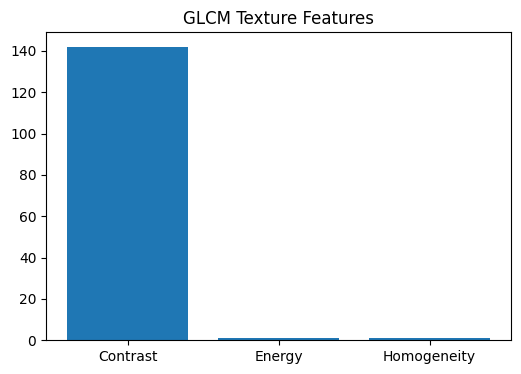

Insight:
- Contrast: 141.8718
- Energy: 0.9565
- Homogeneity: 0.9651
GLCM mendeskripsikan tekstur mikro yang membedakan kelas aritmia.


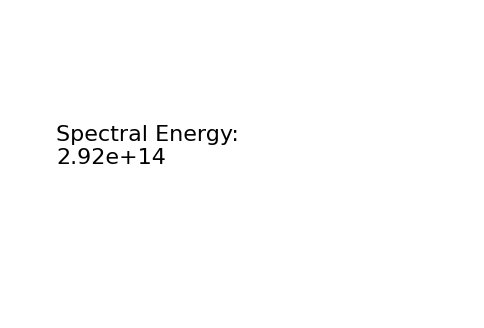

Insight: Semakin besar energi spektral → semakin banyak komponen frekuensi tinggi (QRS tajam).


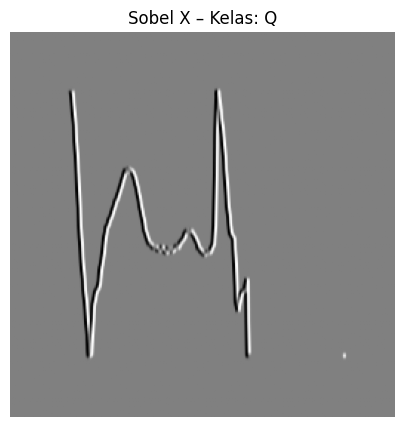

Insight: Sobel X menonjolkan perubahan intensitas arah horizontal. Pada ECG, puncak QRS sering terlihat jelas.


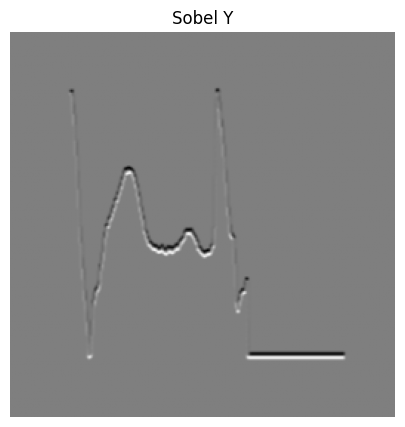

Insight: Sobel Y menonjolkan kontur vertikal, berguna untuk melihat ketebalan garis ECG.


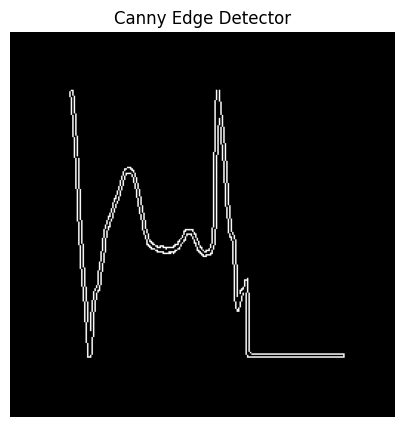

Insight: Canny menghasilkan edge yang paling bersih, membantu mendeteksi pola QRS yang tajam.


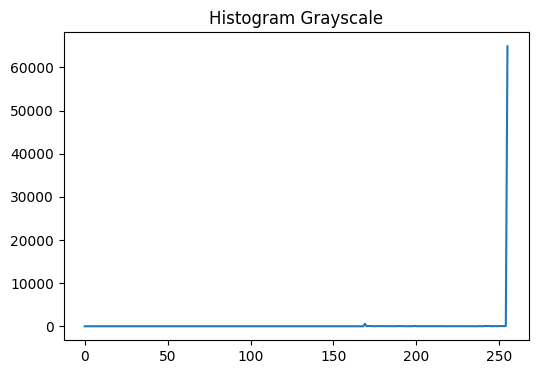

Insight: Histogram grayscale memberi gambaran distribusi intensitas. ECG biasanya dominan warna gelap.


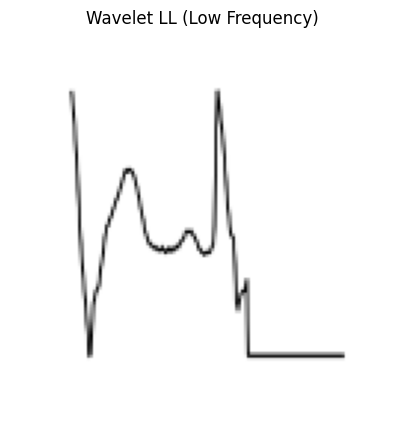

Insight: LL menampilkan bentuk global ECG tanpa detail—penting untuk membedakan baseline wandering.


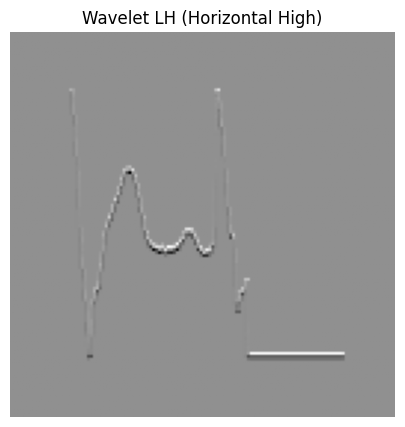

Insight: LH menonjolkan perubahan horizontal → sangat berkaitan dengan bentuk puncak QRS.


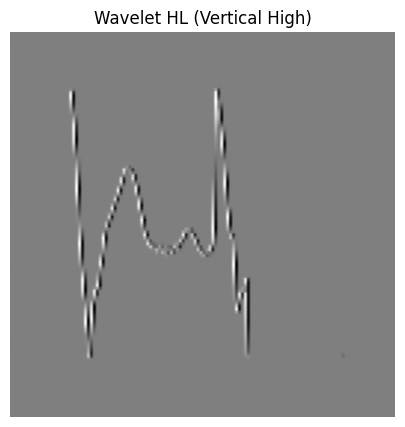

Insight: HL memperlihatkan detail vertikal, cocok untuk memisahkan noise vs sinyal.


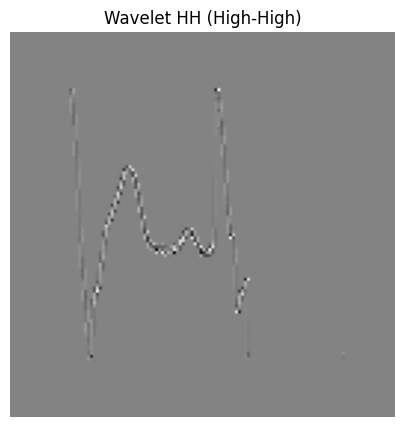

Insight: HH menunjukkan komponen frekuensi tinggi—bagian paling sensitif terhadap noise.


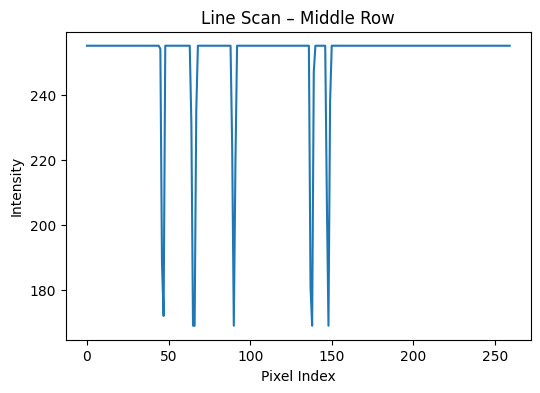

Insight: Line scan mengubah citra ECG ke sinyal 1D. Puncak QRS terlihat sebagai spike intensitas.


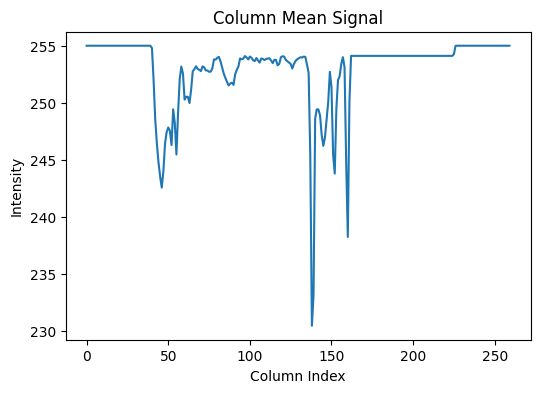

Insight: Column-mean menunjukkan aliran vertikal sinyal ECG untuk mengamati pola ritmis.


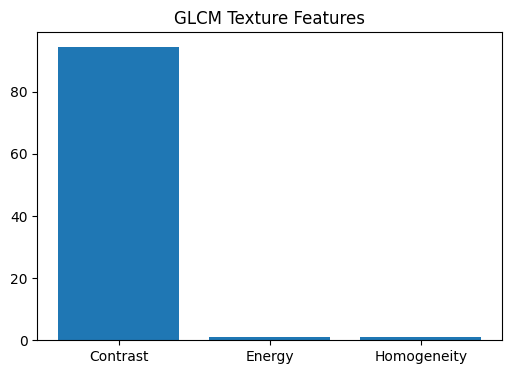

Insight:
- Contrast: 94.3920
- Energy: 0.9502
- Homogeneity: 0.9570
GLCM mendeskripsikan tekstur mikro yang membedakan kelas aritmia.


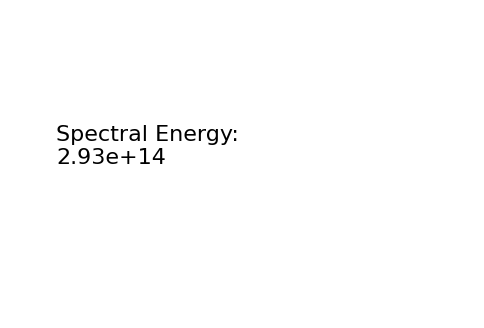

Insight: Semakin besar energi spektral → semakin banyak komponen frekuensi tinggi (QRS tajam).


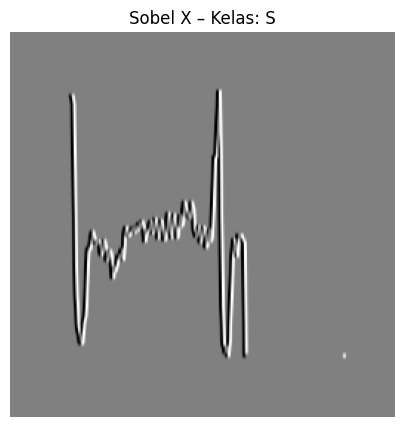

Insight: Sobel X menonjolkan perubahan intensitas arah horizontal. Pada ECG, puncak QRS sering terlihat jelas.


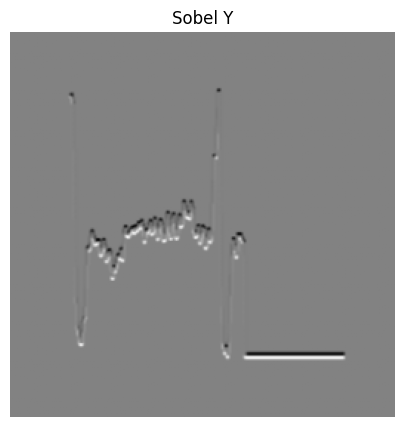

Insight: Sobel Y menonjolkan kontur vertikal, berguna untuk melihat ketebalan garis ECG.


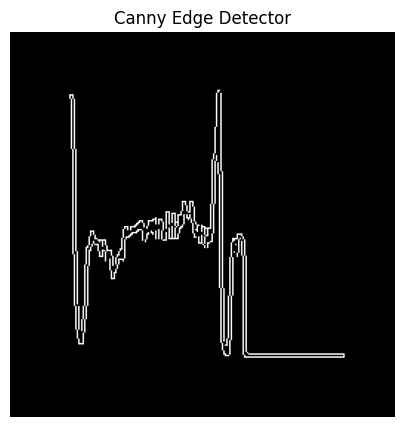

Insight: Canny menghasilkan edge yang paling bersih, membantu mendeteksi pola QRS yang tajam.


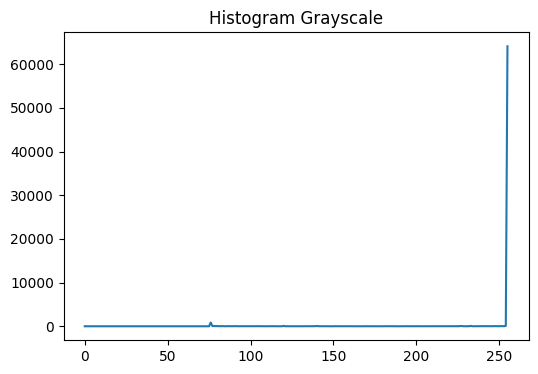

Insight: Histogram grayscale memberi gambaran distribusi intensitas. ECG biasanya dominan warna gelap.


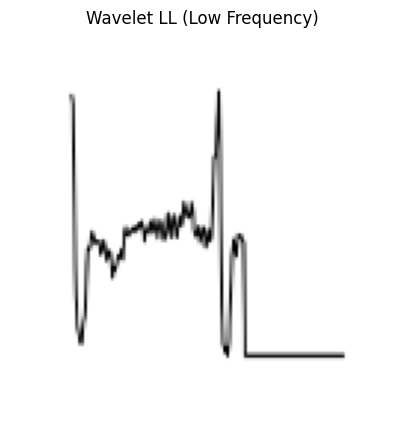

Insight: LL menampilkan bentuk global ECG tanpa detail—penting untuk membedakan baseline wandering.


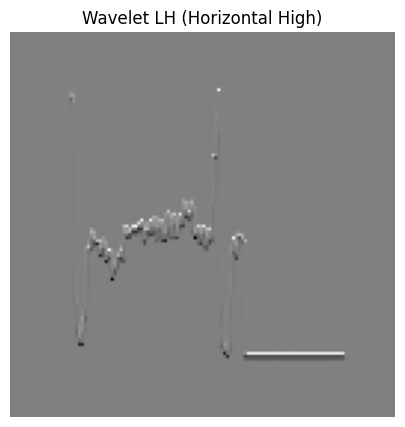

Insight: LH menonjolkan perubahan horizontal → sangat berkaitan dengan bentuk puncak QRS.


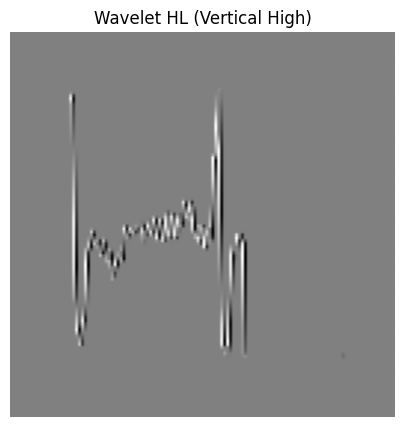

Insight: HL memperlihatkan detail vertikal, cocok untuk memisahkan noise vs sinyal.


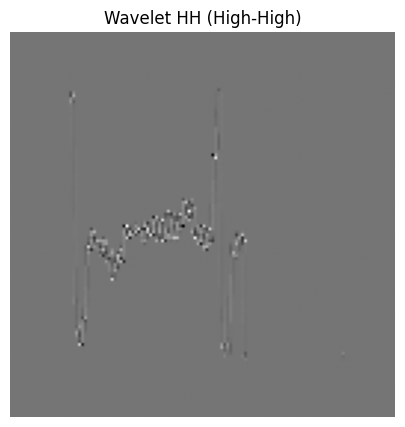

Insight: HH menunjukkan komponen frekuensi tinggi—bagian paling sensitif terhadap noise.


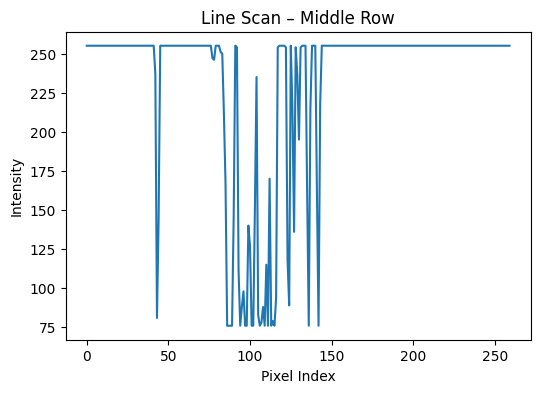

Insight: Line scan mengubah citra ECG ke sinyal 1D. Puncak QRS terlihat sebagai spike intensitas.


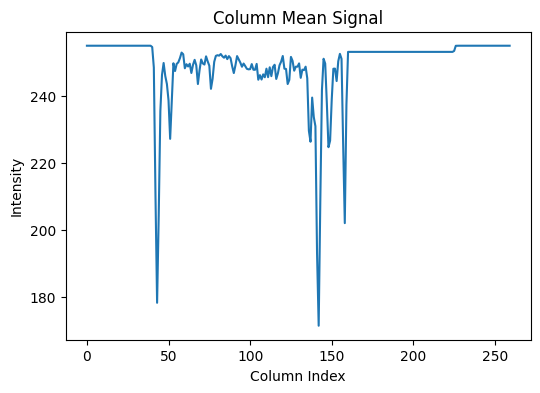

Insight: Column-mean menunjukkan aliran vertikal sinyal ECG untuk mengamati pola ritmis.


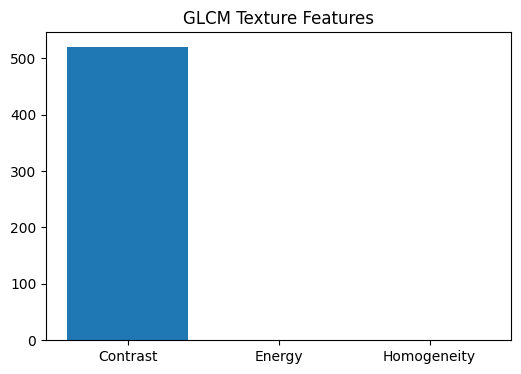

Insight:
- Contrast: 519.7546
- Energy: 0.9366
- Homogeneity: 0.9448
GLCM mendeskripsikan tekstur mikro yang membedakan kelas aritmia.


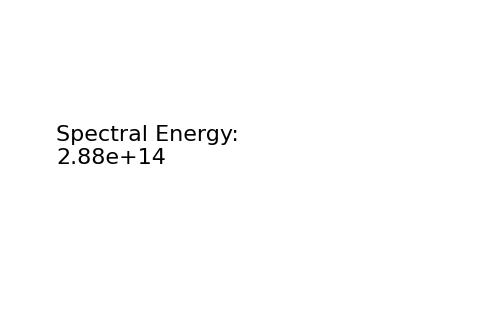

Insight: Semakin besar energi spektral → semakin banyak komponen frekuensi tinggi (QRS tajam).


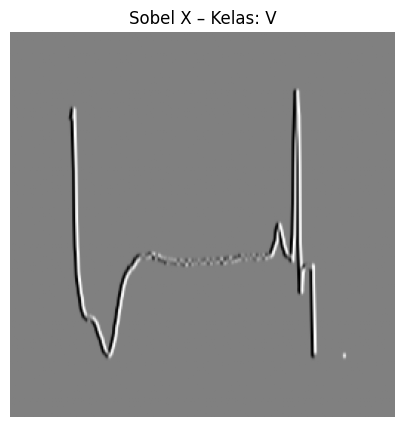

Insight: Sobel X menonjolkan perubahan intensitas arah horizontal. Pada ECG, puncak QRS sering terlihat jelas.


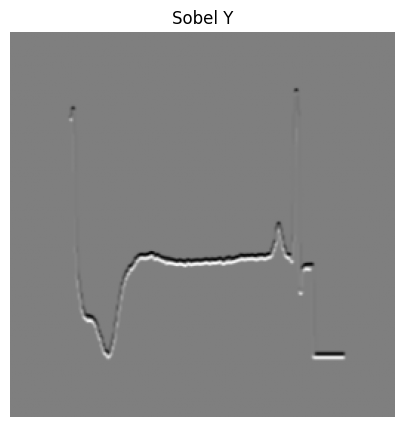

Insight: Sobel Y menonjolkan kontur vertikal, berguna untuk melihat ketebalan garis ECG.


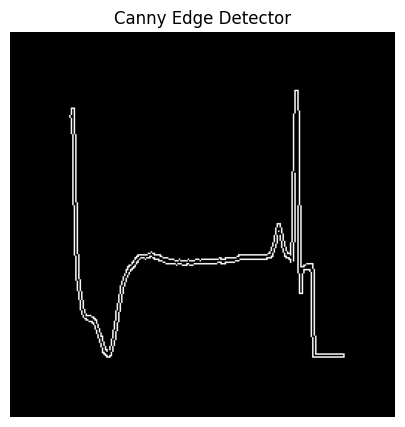

Insight: Canny menghasilkan edge yang paling bersih, membantu mendeteksi pola QRS yang tajam.


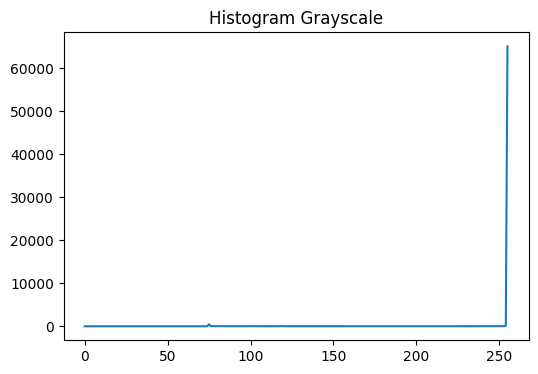

Insight: Histogram grayscale memberi gambaran distribusi intensitas. ECG biasanya dominan warna gelap.


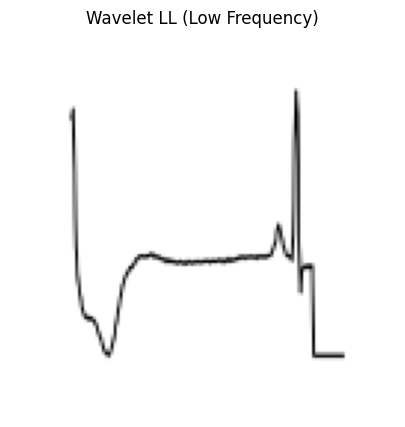

Insight: LL menampilkan bentuk global ECG tanpa detail—penting untuk membedakan baseline wandering.


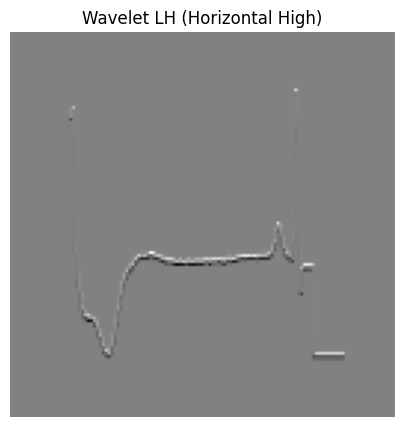

Insight: LH menonjolkan perubahan horizontal → sangat berkaitan dengan bentuk puncak QRS.


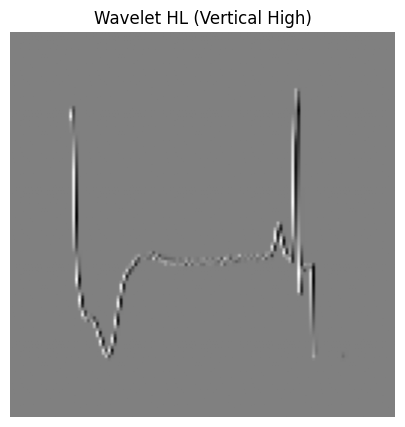

Insight: HL memperlihatkan detail vertikal, cocok untuk memisahkan noise vs sinyal.


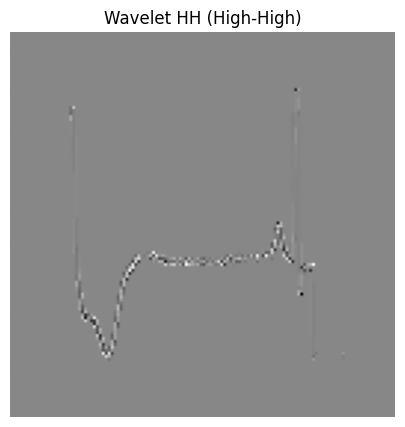

Insight: HH menunjukkan komponen frekuensi tinggi—bagian paling sensitif terhadap noise.


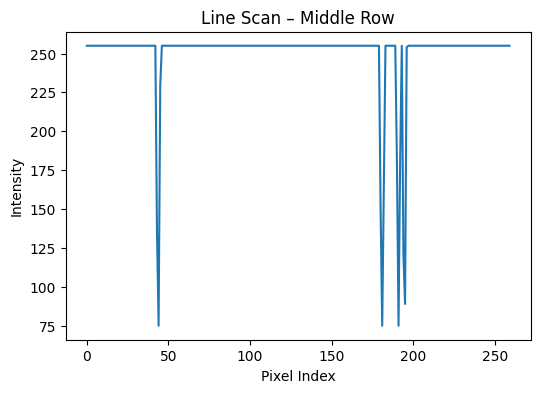

Insight: Line scan mengubah citra ECG ke sinyal 1D. Puncak QRS terlihat sebagai spike intensitas.


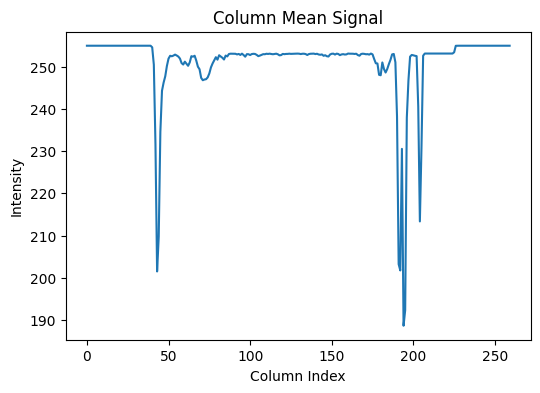

Insight: Column-mean menunjukkan aliran vertikal sinyal ECG untuk mengamati pola ritmis.


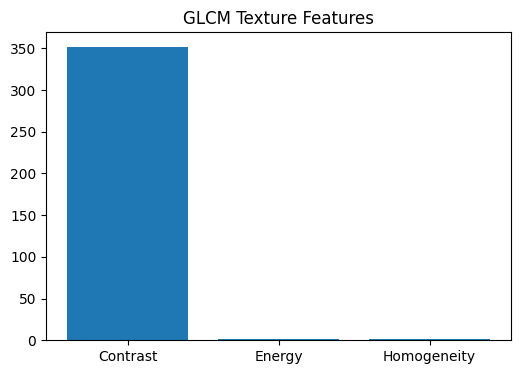

Insight:
- Contrast: 351.5546
- Energy: 0.9553
- Homogeneity: 0.9597
GLCM mendeskripsikan tekstur mikro yang membedakan kelas aritmia.


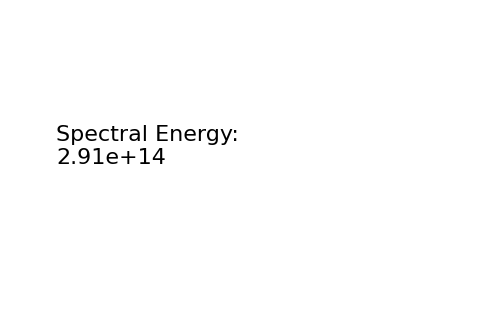

Insight: Semakin besar energi spektral → semakin banyak komponen frekuensi tinggi (QRS tajam).


In [ ]:
# for i, cls in enumerate(class_names):
#     idx = np.where(y_train == i)[0]
#     if len(idx) == 0:
#         continue
#     img = X_train_img[idx[0]]
#     full_signal_insight_separate(img, class_name=cls)
#     print("="*80)
